# India Daily Rainfall Forecasting — BiLSTM vs Transformer (v2)

**Dataset:** `india_weather_rainfall_data.xlsx` (daily station records, 2015–2025)
**Task:** predict the rainfall (mm) of day *t + HORIZON* from the previous `SEQ_LEN` days of weather at the same station.

**Pipeline**
1. Load data and **audit it** (sorted by `date_of_record`? duplicates? missing values?)
2. **Remove every row that has a missing value** (or an impossible value)
3. **Sort by date** and make a **chronological 60 / 20 / 20 split** (train / validation / final test) of the cleaned data
4. Leak-free preprocessing (scaler fitted on the training part only)
5. Sliding windows per station (only windows made of *consecutive* days)
6. Baselines (climatology, persistence)
7. Large **BiLSTM (~0.9 M parameters)** and **Transformer (~1.5 M parameters)**, trained for **150 epochs**
8. Evaluation on validation and the untouched final test set, plots, inference helper

> **What changed in v2**
> * No imputation and no "missing" flags any more: rows with any missing value are **deleted**. Because deleting rows breaks the daily sequence, a window is only used when all its days (and the target day) are present and consecutive.
> * Much bigger models, 150 epochs, AdamW with warm-up + cosine learning-rate decay. The best-validation checkpoint is restored at the end, so more epochs cannot hurt the reported test score through over-fitting.
>
> **Reminder:** the models are trained on `log1p(rainfall)` and evaluated in **mm**; always compare against the baselines.

In [1]:
import os, math, time, pickle, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, precision_recall_curve
from scipy.stats import pearsonr, spearmanr

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

# ------------------------- CONFIGURATION -------------------------
DATA_PATH   = "/kaggle/input/datasets/sam4219/weather-datamsc/india_weather_rainfall_data.xlsx"        # e.g. "/content/india_weather_rainfall_data.xlsx"  (None = auto-search common places)
CACHE_PATH  = "rainfall_raw_cache.pkl"   # first run reads the slow .xlsx, then caches it here
ARTIFACT_DIR = "artifacts"

SEQ_LEN     = 30          # days of history fed to the models
HORIZON     = 1           # 1 = next-day rainfall, 3 = rainfall 3 days ahead, ...
START_DATE  = "2021-01-02"   # before this date >65 % of rainfall/pressure/wind values are missing (not at random) -> unusable
VAL_START   = "2023-04-01"   # train = START_DATE .. VAL_START-1 ; validation = ONE FULL YEAR ; test = from TEST_START
TEST_START  = "2024-04-01"

# True  -> only the TARGET day must lie inside the split; the input window may reach back into the
#          previous split (standard forecasting practice: past data is not leakage).
# False -> the whole window (inputs + target) must lie inside the split.
CONTEXT_FROM_PREVIOUS_SPLIT = True

SEED         = 42
BATCH_SIZE   = 512
EPOCHS       = 40         # MAXIMUM number of epochs - early stopping normally ends training much sooner
EARLY_STOP_PATIENCE  = 6      # stop when validation loss has not improved for this many epochs
EARLY_STOP_MIN_DELTA = 1e-4   # minimum improvement that counts
WARMUP_EPOCHS = 1
MIN_LR_RATIO  = 0.01      # cosine decay goes down to LR * 0.01
WEIGHT_DECAY  = 5e-2
NOISE_STD     = 0.05      # Gaussian noise added to the (standardised) inputs while TRAINING (regulariser)
LR_BILSTM       = 5e-4
LR_TRANSFORMER  = 3e-4
# ---- PINN (physics-informed) loss weights, used by BiLSTM-PINN only ----
LAMBDA_AUX    = 0.3       # weight of the auxiliary next-day weather-state loss
LAMBDA_PHYS   = 0.1       # weight of the physics-residual penalties
W_NONNEG, W_ORDER, W_TEND = 1.0, 1.0, 1.0   # non-negativity / Tmin<=Tavg<=Tmax / bounded 1-day tendency
TEND_QUANTILE = 0.995     # "physically plausible" 1-day change = this quantile of the TRAIN data
RAIN_DAY_MM  = 1.0        # threshold that defines a "rainy day" for the classification-style metrics
QUICK_RUN    = False      # True = tiny subset + 2 epochs, just to smoke-test the notebook

# ---- model sizes: deliberately SMALL (~0.15 M / ~0.1 M parameters; exact numbers are printed later) ----
# v2 used 0.9 M / 1.5 M parameters and over-fitted after 2-4 epochs on ~2 years of effective training data.
BILSTM_CFG = dict(hidden=64, layers=2, dropout=0.30, head=64)
TRF_CFG    = dict(d_model=64, nhead=4, layers=2, ff=128, dropout=0.20, head=64)
K_NEIGH      = 6          # number of nearest stations used for the neighbour features
CELL_DEG     = 3          # size (degrees) of the regional cells
RUN_GBM_REFERENCE = True  # sklearn gradient-boosting reference on the same windows (a sanity ceiling for the networks)

if QUICK_RUN: EPOCHS = 2
os.makedirs(ARTIFACT_DIR, exist_ok=True)

In [2]:
def find_data_file():
    candidates = ([DATA_PATH] if DATA_PATH else []) + [
        "india_weather_rainfall_data.xlsx",
        "/content/india_weather_rainfall_data.xlsx",
        "/content/drive/MyDrive/india_weather_rainfall_data.xlsx",
        "/kaggle/working/india_weather_rainfall_data.xlsx",
        "/mnt/user-data/uploads/india_weather_rainfall_data.xlsx",
    ]
    for p in candidates:
        if p and os.path.exists(p):
            return p
    raise FileNotFoundError("Could not find the .xlsx - set DATA_PATH in the configuration cell.")

if os.path.exists(CACHE_PATH):
    raw = pd.read_pickle(CACHE_PATH)
    print("Loaded cached copy:", CACHE_PATH)
else:
    path = find_data_file()
    print("Reading", path, "(slow, please wait)...")
    t0 = time.time()
    raw = pd.read_excel(path, engine="openpyxl")
    raw.to_pickle(CACHE_PATH)
    print(f"Read in {time.time()-t0:.0f}s and cached to {CACHE_PATH}")

raw["date_of_record"] = pd.to_datetime(raw["date_of_record"])
print(raw.shape)
raw.head()

Reading /kaggle/input/datasets/sam4219/weather-datamsc/india_weather_rainfall_data.xlsx (slow, please wait)...
Read in 115s and cached to rainfall_raw_cache.pkl
(970339, 15)


,date_of_record,month,season,station_name,state,district,avg_temp,min_temp,max_temp,wind_speed,air_pressure,elevation,latitude,longitude,rainfall
0,2021-01-02,January,Winter,Gulmarg,JK,Baramulla,-2.2,-6.6,-0.8,2.2,1020.0,2652,34.05,74.4,0.1
1,2021-01-03,January,Winter,Gulmarg,JK,Baramulla,-3.6,-4.6,-1.8,3.7,1019.5,2652,34.05,74.4,4.4
2,2021-01-04,January,Winter,Gulmarg,JK,Baramulla,-3.0,-4.5,-1.1,2.1,1022.0,2652,34.05,74.4,2.3
3,2021-01-05,January,Winter,Gulmarg,JK,Baramulla,-3.3,-5.1,-1.2,2.8,1015.6,2652,34.05,74.4,35.0
4,2021-01-06,January,Winter,Gulmarg,JK,Baramulla,-3.9,-8.3,-1.0,3.4,1015.3,2652,34.05,74.4,25.5


In [3]:
d = raw["date_of_record"]
n_back = int((d.diff().dt.days < 0).sum())

print("Rows                     :", f"{len(raw):,}")
print("Date range               :", d.min().date(), "->", d.max().date())
print("Globally sorted by date? :", bool(d.is_monotonic_increasing))
print("Backward date jumps      :", n_back, "  <- the file restarts from an early date every time a new station starts")
print()
print("Missing values per column:")
print(raw.isna().sum().to_frame("n_missing").assign(pct=lambda x: (100*x.n_missing/len(raw)).round(1)))

Rows                     : 970,339
Date range               : 2015-01-01 -> 2025-02-10
Globally sorted by date? : False
Backward date jumps      : 413   <- the file restarts from an early date every time a new station starts

Missing values per column:
                n_missing   pct
date_of_record          0   0.0
month                   0   0.0
season                  0   0.0
station_name            0   0.0
state                   0   0.0
district                0   0.0
avg_temp                0   0.0
min_temp            43898   4.5
max_temp           110598  11.4
wind_speed         274444  28.3
air_pressure       304664  31.4
elevation               0   0.0
latitude                0   0.0
longitude               0   0.0
rainfall           257554  26.5


In [4]:
# ---- WHERE is the missing data? (this explains most of the poor v2 results) ----
yr = raw["date_of_record"].dt.year
cols = ["rainfall", "wind_speed", "air_pressure", "max_temp", "min_temp"]
print("Share of missing values per year (fraction of rows):")
display(raw[cols].isna().groupby(yr).mean().round(2).assign(rows=raw.groupby(yr).size(), stations=raw.groupby(yr)["station_name"].nunique()))

early, late = raw[yr <= 2020], raw[yr >= 2021]
mo = early["date_of_record"].dt.month
print("\n2015-2020: share of rows with missing rainfall, by month  (dry months are missing most -> NOT random):")
print(early["rainfall"].isna().groupby(mo).mean().round(2).to_dict())
print(f"zero-rain share among OBSERVED rows:  2015-2020 = {(early['rainfall'].dropna()==0).mean():.2f}   2021+ = {(late['rainfall'].dropna()==0).mean():.2f}")
print("=> rows that survive 'delete every row with a NaN' in 2015-2020 are biased toward rainy days. v3 therefore starts at START_DATE.")

Share of missing values per year (fraction of rows):


,rainfall,wind_speed,air_pressure,max_temp,min_temp,rows,stations
date_of_record,,,,,,,
2015,0.69,0.89,0.97,0.09,0.25,44728,167
2016,0.71,0.79,0.91,0.33,0.11,61183,175
2017,0.69,0.77,0.87,0.33,0.10,61616,176
2018,0.70,0.72,0.82,0.30,0.09,63411,185
2019,0.67,0.69,0.77,0.32,0.10,66224,189
2020,0.67,0.68,0.69,0.38,0.11,67532,193
2021,0.03,0.01,0.01,0.00,0.00,141866,402
2022,0.01,0.00,0.00,0.00,0.00,149392,404
2023,0.00,0.00,0.00,0.00,0.00,149788,405



2015-2020: share of rows with missing rainfall, by month  (dry months are missing most -> NOT random):
{1: 0.9, 2: 0.91, 3: 0.84, 4: 0.79, 5: 0.71, 6: 0.49, 7: 0.34, 8: 0.35, 9: 0.49, 10: 0.72, 11: 0.83, 12: 0.88}
zero-rain share among OBSERVED rows:  2015-2020 = 0.33   2021+ = 0.55
=> rows that survive 'delete every row with a NaN' in 2015-2020 are biased toward rainy days. v3 therefore starts at START_DATE.


In [5]:
# A station *name* is not unique: some names refer to 2 physically different stations.
def make_station_id(x):
    return (x["station_name"].astype(str) + "|" + x["latitude"].round(4).astype(str) + "|"
            + x["longitude"].round(4).astype(str) + "|" + x["elevation"].astype(str))

raw["station_id"] = make_station_id(raw)

print("Unique station names :", raw["station_name"].nunique())
print("Unique station_ids   :", raw["station_id"].nunique())
print("Fully duplicated rows                :", int(raw.duplicated().sum()))
print("Duplicate (date, station_name) rows  :", int(raw.duplicated(["date_of_record", "station_name"]).sum()), " <- two different stations sharing one name")
print("Duplicate (date, station_id)   rows  :", int(raw.duplicated(["date_of_record", "station_id"]).sum()))
assert not raw.duplicated(["date_of_record", "station_id"]).any()

multi = raw.groupby("station_name")["station_id"].nunique()
print("\nNames shared by >1 physical station:", multi[multi > 1].index.tolist())

Unique station names : 406
Unique station_ids   : 414
Fully duplicated rows                : 0
Duplicate (date, station_name) rows  : 21703  <- two different stations sharing one name
Duplicate (date, station_id)   rows  : 0

Names shared by >1 physical station: ['Agra', 'Akola', 'Car Nicobar', 'Jamshedpur', 'Madurai', 'Siliguri', 'Srinagar', 'Thiruvananthapuram']


In [6]:
NEEDED    = ["avg_temp", "min_temp", "max_temp", "wind_speed", "air_pressure", "rainfall"]
USED_COLS = ["date_of_record", "station_name", "latitude", "longitude", "elevation"] + NEEDED   # everything used downstream

def null_report(frame, cols, title):
    """Prints the number of NaN / +-inf cells per column and returns the number of rows with >=1 null."""
    num = frame[cols].select_dtypes("number")
    nan_n = frame[cols].isna().sum()
    inf_n = pd.Series(np.isinf(num.to_numpy(dtype="float64")).sum(axis=0), index=num.columns).reindex(cols).fillna(0).astype(int)
    bad = pd.DataFrame({"NaN": nan_n, "inf": inf_n}); bad = bad[(bad > 0).any(axis=1)]
    rows = int((frame[cols].isna().any(axis=1) | ~np.isfinite(frame[cols].select_dtypes("number").to_numpy(dtype="float64")).all(axis=1)).sum())
    print(f"[null check] {title}: {rows:,} rows contain >=1 null/inf in the {len(cols)} checked columns")
    if len(bad): display(bad)
    return rows

n0 = len(raw)
null_report(raw, USED_COLS, "BEFORE cleaning")

nonfinite   = ~np.isfinite(raw[NEEDED].to_numpy(dtype="float64")).all(axis=1)          # NaN or +-inf in a model variable
has_missing = raw[USED_COLS].isna().any(axis=1) | nonfinite
bad_range   = raw["max_temp"] > 50
print(f"rows with >=1 missing value : {int(has_missing.sum()):,}  ({100*has_missing.mean():.1f}%)")
print(f"rows with max_temp > 50 degC: {int((bad_range & ~has_missing).sum()):,} (not already missing)")
print(f"rows with negative rainfall : {int((raw['rainfall'] < 0).sum()):,}  (reported only; clipped at 0 when features are built)")

in_period = raw["date_of_record"] >= pd.Timestamp(START_DATE)
print(f"rows before START_DATE ({START_DATE}) dropped: {int((~in_period).sum()):,}")
clean = raw.loc[~has_missing & ~bad_range & in_period].reset_index(drop=True)

# ---- hard guarantees: nothing null survives ----
assert null_report(clean, USED_COLS, "AFTER cleaning") == 0, "null values survived the cleaning step!"
assert clean[USED_COLS].notna().all().all()
assert np.isfinite(clean[NEEDED].to_numpy(dtype="float64")).all()
print(f"\nrows before: {n0:,}   after: {len(clean):,}   kept: {100*len(clean)/n0:.1f}%   stations left: {clean['station_id'].nunique()}")

print("\nRows kept per year:")
print(pd.DataFrame({"before": raw.groupby(raw["date_of_record"].dt.year).size(),
                    "after":  clean.groupby(clean["date_of_record"].dt.year).size()}).fillna(0).astype(int))

[null check] BEFORE cleaning: 353,397 rows contain >=1 null/inf in the 11 checked columns


,NaN,inf
min_temp,43898,0
max_temp,110598,0
wind_speed,274444,0
air_pressure,304664,0
rainfall,257554,0


rows with >=1 missing value : 353,397  (36.4%)
rows with max_temp > 50 degC: 2 (not already missing)
rows with negative rainfall : 0  (reported only; clipped at 0 when features are built)
rows before START_DATE (2021-01-02) dropped: 364,879
[null check] AFTER cleaning: 0 rows contain >=1 null/inf in the 11 checked columns

rows before: 970,339   after: 597,294   kept: 61.6%   stations left: 414

Rows kept per year:
                before   after
date_of_record                
2015             44728       0
2016             61183       0
2017             61616       0
2018             63411       0
2019             66224       0
2020             67532       0
2021            141866  136667
2022            149392  147417
2023            149788  149781
2024            147826  146656
2025             16773   16773


## 5. Feature engineering
Because all missing rows were removed there is nothing to impute and no missing-flags are needed. The only fitted quantity (the scaler) comes **only from the training part**.

| group | features |
|---|---|
| weather | `avg_temp, min_temp, max_temp, temp_range, wind_speed, air_pressure` |
| rain history | `rain_log = log1p(rainfall)` |
| station | `latitude, longitude, elevation` |
| season | `doy_sin, doy_cos` (day of year) |

**Target:** `log1p(rainfall)` of day *t + HORIZON*.

Sorted by date_of_record: True
train/val cut: 2023-04-01   val/test cut: 2024-04-01


,rows,first_date,last_date,stations,mean_rain_mm,row_share_%
split_code,,,,,,
train,321063,2021-01-02,2023-03-31,412,4.107763,53.8
val,150294,2023-04-01,2024-03-31,413,3.736071,25.2
test,125937,2024-04-01,2025-02-10,412,4.817660,21.1


Months present in each split (a split that misses months cannot be compared with the others):


date_of_record,1,2,3,4,5,6,7,8,9,10,11,12
split_code,,,,,,,,,,,,
train,35632,32459,35968,22551,22767,23020,24894,25097,24316,25064,24236,25059
val,12772,11948,12772,12300,12710,12300,12710,12710,12275,12725,12330,12742
test,12683,4090,0,12360,12772,12360,12772,11213,10810,12772,12326,11779


OK: train < validation < test in time, no overlap.


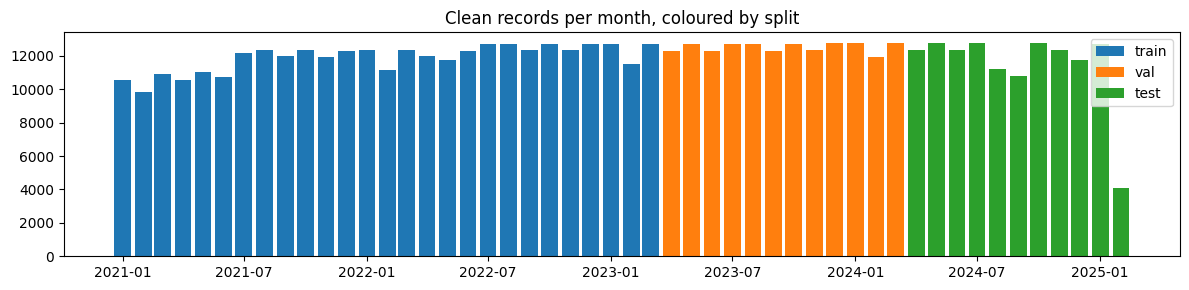

In [7]:
# ---- 4.1 sort by date (then station for a deterministic order) ----
df = clean.sort_values(["date_of_record", "station_id"], kind="stable").reset_index(drop=True)
assert df["date_of_record"].is_monotonic_increasing
print("Sorted by date_of_record:", bool(df["date_of_record"].is_monotonic_increasing))

# ---- 4.2 calendar cuts (validation = one FULL year so that it contains every season) ----
n = len(df)
train_cut = pd.Timestamp(VAL_START)     # first date of validation
val_cut   = pd.Timestamp(TEST_START)    # first date of test

def split_of(dates):
    return np.select([dates < train_cut, dates < val_cut], [0, 1], default=2)   # 0=train 1=val 2=test

df["split_code"] = split_of(df["date_of_record"].values)
SPLIT_NAMES = ["train", "val", "test"]

summary = (df.groupby("split_code")
             .agg(rows=("rainfall", "size"), first_date=("date_of_record", "min"), last_date=("date_of_record", "max"),
                  stations=("station_id", "nunique"), mean_rain_mm=("rainfall", "mean"))
             .rename(index=dict(enumerate(SPLIT_NAMES))))
summary["row_share_%"] = (100 * summary["rows"] / n).round(1)
print(f"train/val cut: {train_cut.date()}   val/test cut: {val_cut.date()}")
display(summary)
print("Months present in each split (a split that misses months cannot be compared with the others):")
display(pd.crosstab(df["split_code"].map(dict(enumerate(SPLIT_NAMES))), df["date_of_record"].dt.month).reindex(SPLIT_NAMES))

# ---- 4.3 hard checks: no chronological overlap ----
mx = df.groupby("split_code")["date_of_record"].max(); mn = df.groupby("split_code")["date_of_record"].min()
assert mx[0] < mn[1] and mx[1] < mn[2], "splits overlap in time!"
print("OK: train < validation < test in time, no overlap.")

# ---- 4.4 picture of the split ----
m = df.assign(month=df["date_of_record"].dt.to_period("M").dt.to_timestamp()).groupby(["month", "split_code"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(12, 3))
for c, col in zip(m.columns, ["tab:blue", "tab:orange", "tab:green"]):
    ax.bar(m.index, m[c], width=25, color=col, label=SPLIT_NAMES[c])
ax.set_title("Clean records per month, coloured by split"); ax.legend(); plt.tight_layout(); plt.show()

# ---- 4.5 per-station, date-ordered table used for windowing (stations contiguous, dates increasing) ----
daily = df.sort_values(["station_id", "date_of_record"], kind="stable").reset_index(drop=True)

In [8]:
WEATHER   = ["avg_temp", "min_temp", "max_temp", "wind_speed", "air_pressure"]
STATIC    = ["latitude", "longitude", "elevation"]
REG_COLS  = ["dp_own", "nb_lr", "nb_lrmax", "nb_dp", "nb_dT", "nb_wind", "reg_lr", "nat_lr", "nat_dp"]
CONT_COLS = ["avg_temp", "min_temp", "max_temp", "temp_range", "wind_speed", "air_pressure",
             "rain_log", "latitude", "longitude", "elevation"] + REG_COLS     # standardised
CYC_COLS  = ["doy_sin", "doy_cos"]
FEATURES  = CONT_COLS + CYC_COLS
N_FEAT    = len(FEATURES)
AUX_COLS  = ["avg_temp", "min_temp", "max_temp", "wind_speed", "air_pressure"]   # weather state predicted by the PINN as auxiliary outputs
AUX_IDX   = [FEATURES.index(c) for c in AUX_COLS]

# ---------------- neighbour / regional features (computed from the whole station network) ----------------
stations = raw.drop_duplicates("station_id").set_index("station_id")[["latitude", "longitude"]].sort_index()
ST_IDS   = stations.index.values;  N_ST = len(ST_IDS)
ST_POS   = {s: i for i, s in enumerate(ST_IDS)}
_xy      = np.c_[stations["latitude"].values, stations["longitude"].values * np.cos(np.deg2rad(stations["latitude"].values))]
_D       = ((_xy[:, None, :] - _xy[None, :, :]) ** 2).sum(-1); np.fill_diagonal(_D, 1e9)
NB       = np.argsort(_D, axis=1)[:, :K_NEIGH]                                   # (N_ST, K) nearest stations
_cell    = (np.floor(stations["latitude"].values / CELL_DEG).astype(int).astype(str) + "_" +
            np.floor(stations["longitude"].values / CELL_DEG).astype(int).astype(str))
_cu, CELL_CODE = np.unique(_cell, return_inverse=True)
CELL_M   = np.eye(len(_cu))[CELL_CODE]                                           # (N_ST, N_CELLS) one-hot

def regional_features(frame):
    """frame: RAW rows of many stations (NaN allowed). Needs the day BEFORE the first wanted day (for the 1-day changes).
       Returns a DataFrame with the keys (date_of_record, station_id) and the REG_COLS."""
    d0, d1 = frame["date_of_record"].min(), frame["date_of_record"].max()
    days = pd.date_range(d0, d1)
    def grid(col):
        g = frame.pivot(index="date_of_record", columns="station_id", values=col).reindex(index=days, columns=ST_IDS)
        return g.to_numpy(dtype="float64")                                       # (T, N_ST)
    lr   = np.log1p(np.clip(grid("rainfall"), 0, None))
    pres, avg, wind = grid("air_pressure"), grid("avg_temp"), grid("wind_speed")
    d1d  = lambda a: np.vstack([np.full((1, a.shape[1]), np.nan), np.diff(a, axis=0)])
    dp, dT = d1d(pres), d1d(avg)
    nb_mean = lambda a: np.nanmean(a[:, NB], axis=2)
    nb_max  = lambda a: np.nanmax(a[:, NB], axis=2)
    def cell_mean(a):
        m = ~np.isnan(a)
        with np.errstate(invalid="ignore", divide="ignore"):
            return ((np.where(m, a, 0.0) @ CELL_M) / (m.astype(float) @ CELL_M))[:, CELL_CODE]
    nat = lambda a: np.repeat(np.nanmean(a, axis=1, keepdims=True), a.shape[1], axis=1)
    G = {"dp_own": dp, "nb_lr": nb_mean(lr), "nb_lrmax": nb_max(lr), "nb_dp": nb_mean(dp), "nb_dT": nb_mean(dT),
         "nb_wind": nb_mean(wind), "reg_lr": cell_mean(lr), "nat_lr": nat(lr), "nat_dp": nat(dp)}
    ti = (frame["date_of_record"] - d0).dt.days.to_numpy()
    si = frame["station_id"].map(ST_POS).to_numpy()
    out = pd.DataFrame({k: v[ti, si] for k, v in G.items()}, index=frame.index)
    out["date_of_record"], out["station_id"] = frame["date_of_record"].values, frame["station_id"].values
    return out

raw_recent = raw[raw["date_of_record"] >= pd.Timestamp(START_DATE) - pd.Timedelta(days=1)]
t0 = time.time()
reg_tbl = regional_features(raw_recent)
daily = daily.merge(reg_tbl[["date_of_record", "station_id"] + REG_COLS], on=["date_of_record", "station_id"], how="left")
REG_FILL = daily.loc[daily["split_code"] == 0, REG_COLS].median()                 # fill values from TRAIN only
print(f"regional features built in {time.time()-t0:.0f}s | NaN share before fill:\n{daily[REG_COLS].isna().mean().round(4).to_dict()}")
daily[REG_COLS] = daily[REG_COLS].fillna(REG_FILL)

def make_features(dd):
    f = pd.DataFrame(index=dd.index)
    for c in WEATHER: f[c] = dd[c]
    f["temp_range"] = dd["max_temp"] - dd["min_temp"]
    f["rain_log"]   = np.log1p(dd["rainfall"].clip(lower=0))
    for c in STATIC:   f[c] = dd[c]
    for c in REG_COLS: f[c] = dd[c]
    doy = dd["date_of_record"].dt.dayofyear.values
    f["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
    f["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
    return f[FEATURES].astype("float32")

feat = make_features(daily)
train_rows = daily["split_code"].values == 0
scaler = StandardScaler().fit(feat.loc[train_rows, CONT_COLS])      # fit on TRAIN only
feat[CONT_COLS] = scaler.transform(feat[CONT_COLS]).astype("float32")

X = feat[FEATURES].values.astype("float32")                          # (n_rows, N_FEAT)
Y = np.log1p(daily["rainfall"].values).astype("float32")             # target (never missing now)
assert np.isfinite(X).all() and np.isfinite(Y).all(), "null/inf found in the feature matrix or target!"
print("[null check] feature matrix X and target Y: no NaN / inf")
print("Feature matrix:", X.shape, "| features:", N_FEAT)

regional features built in 1s | NaN share before fill:
{'dp_own': 0.0025, 'nb_lr': 0.0, 'nb_lrmax': 0.0, 'nb_dp': 0.0014, 'nb_dT': 0.0004, 'nb_wind': 0.0, 'reg_lr': 0.0, 'nat_lr': 0.0, 'nat_dp': 0.0}
[null check] feature matrix X and target Y: no NaN / inf
Feature matrix: (597294, 21) | features: 21


In [9]:
L, H = SEQ_LEN, HORIZON
dates      = daily["date_of_record"].values
sid        = daily["station_id"].values
pos        = daily.groupby("station_id", sort=False).cumcount().values   # position of the row inside its station
split_arr  = daily["split_code"].values
j          = np.arange(len(daily))

ok = pos >= L - 1 + H                                                    # enough earlier rows in the same station
first_input = np.where(ok, j - H - L + 1, 0)
ok &= (dates - dates[first_input]) == np.timedelta64(L - 1 + H, "D")     # ...and they are consecutive calendar days
n_gap_removed = int(((pos >= L - 1 + H)).sum() - ok.sum())
if not CONTEXT_FROM_PREVIOUS_SPLIT:                                      # whole window must also lie inside the split
    ok &= split_arr[first_input] == split_arr

tgt_idx = {name: j[ok & (split_arr == code)] for code, name in enumerate(SPLIT_NAMES)}
print(f"rows that could be targets but were rejected because the window contains a removed day: {n_gap_removed:,}")

if QUICK_RUN:
    rng = np.random.default_rng(SEED)
    for k, keep in [("train", 30000), ("val", 10000), ("test", 10000)]:
        t = tgt_idx[k]; tgt_idx[k] = np.sort(rng.choice(t, size=min(keep, len(t)), replace=False))

# ---------------- leakage / correctness checks ----------------
for code_, k in enumerate(SPLIT_NAMES):
    t = tgt_idx[k]
    assert (split_arr[t] == code_).all(), f"{k}: target outside its split"
    first = t - H - L + 1
    assert (sid[first] == sid[t]).all(), f"{k}: a window crosses two stations"
    assert (dates[first] + np.timedelta64(L - 1 + H, "D") == dates[t]).all(), f"{k}: window not consecutive days"
assert dates[tgt_idx["train"]].max() < dates[tgt_idx["val"]].min() <= dates[tgt_idx["val"]].max() < dates[tgt_idx["test"]].min()
print("All window checks passed (single station, consecutive days, no missing day, inputs strictly before target, targets in correct split).\n")

win_summary = pd.DataFrame({k: {"windows": len(v),
                                "target_from": pd.Timestamp(dates[v].min()).date(),
                                "target_to":   pd.Timestamp(dates[v].max()).date(),
                                "mean_rain_mm": float(np.expm1(Y[v]).mean())} for k, v in tgt_idx.items()}).T
display(win_summary)

rows that could be targets but were rejected because the window contains a removed day: 36,084
All window checks passed (single station, consecutive days, no missing day, inputs strictly before target, targets in correct split).



,windows,target_from,target_to,mean_rain_mm
train,297046,2021-02-01,2023-03-31,4.093803
val,150204,2023-04-01,2024-03-31,3.738026
test,101540,2024-04-01,2025-02-10,5.049184


In [10]:
tr_ = daily.loc[daily["split_code"] == 0, ["station_id", "date_of_record", "avg_temp", "air_pressure"]]
g_  = tr_.groupby("station_id", sort=False)
consec = (g_["date_of_record"].diff().dt.days == 1)                      # only differences between consecutive calendar days
dT_ = g_["avg_temp"].diff().abs()[consec];  dP_ = g_["air_pressure"].diff().abs()[consec]
DT_MAX = float(dT_.quantile(TEND_QUANTILE))        # degC per day
DP_MAX = float(dP_.quantile(TEND_QUANTILE))        # hPa per day
print(f"plausible 1-day change (train, {TEND_QUANTILE:.1%} quantile):  temperature {DT_MAX:.2f} degC | pressure {DP_MAX:.2f} hPa")
assert np.isfinite(DT_MAX) and np.isfinite(DP_MAX) and DT_MAX > 0 and DP_MAX > 0

plausible 1-day change (train, 99.5% quantile):  temperature 4.40 degC | pressure 4.40 hPa


In [11]:
rain_mm   = daily["rainfall"].values
month_arr = daily["date_of_record"].dt.month.values
y_mm      = {k: rain_mm[tgt_idx[k]] for k in SPLIT_NAMES}

# ---- climatology from TRAIN observations only ----
trn = daily[daily["split_code"] == 0].assign(month=lambda x: x["date_of_record"].dt.month)
clim_sm  = trn.groupby(["station_id", "month"])["rainfall"].mean()
clim_m   = trn.groupby("month")["rainfall"].mean()
clim_all = trn["rainfall"].mean()

def climatology(rows):
    keys = pd.MultiIndex.from_arrays([sid[rows], month_arr[rows]])
    v  = clim_sm.reindex(keys).values
    fb = clim_m.reindex(month_arr[rows]).values
    return np.nan_to_num(np.where(np.isnan(v), fb, v), nan=clim_all)

def persistence(rows):
    return rain_mm[rows - H]                      # rainfall on the last input day (always present in a valid window)

# ---- metric helpers ----
def _corr(a, b, fn):
    return float("nan") if (np.std(a) == 0 or np.std(b) == 0) else float(fn(a, b)[0])

def reg_metrics(y, p):
    e = p - y
    return {"RMSE": np.sqrt(np.mean(e ** 2)),
            "R2":   1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2),
            "PCC":  _corr(y, p, pearsonr),            # Pearson correlation coefficient
            "SCC":  _corr(y, p, spearmanr),           # Spearman rank correlation coefficient
            "MAE":  np.mean(np.abs(e)), "Bias": np.mean(e),
            "RMSE_log": np.sqrt(np.mean((np.log1p(p) - np.log1p(y)) ** 2))}

def best_threshold(y_bin, score):
    prec, rec, thr = precision_recall_curve(y_bin, score)
    f1 = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
    return thr[np.argmax(f1)]

def evaluate(name, preds):
    """preds: dict split -> predictions in mm. Returns a tidy DataFrame (val + test)."""
    thr = best_threshold(y_mm["val"] >= RAIN_DAY_MM, preds["val"])          # tuned on VALIDATION only
    out = {}
    for s in ["val", "test"]:
        yb, pb = y_mm[s] >= RAIN_DAY_MM, preds[s] >= thr
        tp = (yb & pb).sum(); prec = tp / max(pb.sum(), 1); rec = tp / max(yb.sum(), 1)
        m = reg_metrics(y_mm[s], preds[s])
        m.update({"AUC(rain)": roc_auc_score(yb, preds[s]), "F1(rain)": 2 * prec * rec / max(prec + rec, 1e-12),
                  "Precision": prec, "Recall": rec})
        out[(s, name)] = m
    return pd.DataFrame(out).T

predictions = {"Climatology": {s: climatology(tgt_idx[s]) for s in SPLIT_NAMES},
               "Persistence": {s: persistence(tgt_idx[s]) for s in SPLIT_NAMES}}

results = pd.concat([evaluate(k, v) for k, v in predictions.items()])
results.index.names = ["split", "model"]
results = results.loc[["val", "test"]]
results.round(3)

RMSE     R2    PCC    SCC    MAE   Bias  RMSE_log  AUC(rain)  F1(rain)  Precision  Recall
split model                                                                                                   
val   Climatology  10.281  0.151  0.406  0.576  4.655  0.709     1.133      0.822     0.658      0.588   0.746
      Persistence  11.187 -0.006  0.497  0.688  3.723  0.004     0.872      0.856     0.727      0.676   0.786
test  Climatology  11.588  0.230  0.480  0.658  5.224  0.058     1.094      0.856     0.731      0.672   0.802
      Persistence  12.871  0.050  0.522  0.722  4.759 -0.020     0.936      0.868     0.773      0.731   0.821

In [12]:
# ---- Gradient-boosting reference on the SAME windows / split (sanity ceiling for the neural networks) ----
if RUN_GBM_REFERENCE:
    from sklearn.ensemble import HistGradientBoostingRegressor
    rl_i = FEATURES.index("rain_log")
    def tab(rows):
        last = rows - H                                                  # last input day
        parts = [X[last - k] for k in (0, 1, 2, 3)]                      # day t, t-1, t-2, t-3 (all features)
        r = np.stack([X[last - k, rl_i] for k in range(SEQ_LEN)], 1)     # standardised rain history
        parts += [r[:, :7].mean(1, keepdims=True), r.mean(1, keepdims=True), (r[:, :7] > r[:, :7].min()).mean(1, keepdims=True)]
        return np.hstack(parts)
    T = {k: tab(tgt_idx[k]) for k in SPLIT_NAMES}
    gbm = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.06, max_leaf_nodes=31, min_samples_leaf=100,
                                        l2_regularization=1.0, early_stopping=False, random_state=SEED)
    gbm.fit(T["train"], Y[tgt_idx["train"]])
    yv = Y[tgt_idx["val"]]
    stage_val = [np.mean((p - yv) ** 2) for p in gbm.staged_predict(T["val"])]
    best_it = int(np.argmin(stage_val))
    def pred_at(Xs):
        for i, p in enumerate(gbm.staged_predict(Xs)):
            if i == best_it: return p
    predictions["GBM (reference)"] = {s: np.clip(np.expm1(pred_at(T[s])), 0, None) for s in ["val", "test"]}
    print(f"GBM reference: best iteration {best_it+1} | val MSE on log1p(rain) = {stage_val[best_it]:.4f}")
    results = pd.concat([evaluate(k, v) for k, v in predictions.items()]); results.index.names = ["split", "model"]
    display(results.loc[["val", "test"]].round(3))

GBM reference: best iteration 394 | val MSE on log1p(rain) = 0.4876


RMSE     R2    PCC    SCC    MAE   Bias  RMSE_log  AUC(rain)  F1(rain)  Precision  Recall
split model                                                                                                       
val   Climatology      10.281  0.151  0.406  0.576  4.655  0.709     1.133      0.822     0.658      0.588   0.746
      Persistence      11.187 -0.006  0.497  0.688  3.723  0.004     0.872      0.856     0.727      0.676   0.786
      GBM (reference)   9.486  0.277  0.592  0.741  2.936 -1.794     0.698      0.916     0.763      0.708   0.828
test  Climatology      11.588  0.230  0.480  0.658  5.224  0.058     1.094      0.856     0.731      0.672   0.802
      Persistence      12.871  0.050  0.522  0.722  4.759 -0.020     0.936      0.868     0.773      0.731   0.821
      GBM (reference)  11.032  0.302  0.609  0.786  3.777 -2.271     0.742      0.927     0.809      0.749   0.881

In [13]:
import torch, torch.nn as nn, torch.nn.functional as F

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.__version__)
if device.type == "cpu":
    print("WARNING: no GPU found - training ~1 M-parameter models will be slow on CPU. Use a GPU runtime.")

X_t = torch.from_numpy(X).to(device)
Y_t = torch.from_numpy(Y).to(device)
AUX_IDX_T = torch.tensor(AUX_IDX, dtype=torch.long, device=device)

class WindowLoader:
    """Gathers (SEQ_LEN, N_FEAT) windows on the fly from the big feature matrix.
       Yields: window, log1p(rain) target, next-day weather state (standardised; used ONLY as an auxiliary training target)."""
    def __init__(self, tgt, batch_size, shuffle=False, seed=0):
        self.tgt = torch.as_tensor(tgt, dtype=torch.long)
        self.bs, self.shuffle = batch_size, shuffle
        self.offsets = torch.arange(-SEQ_LEN + 1, 1, dtype=torch.long, device=device)
        self.gen = torch.Generator().manual_seed(seed)
    def __len__(self):
        return math.ceil(len(self.tgt) / self.bs)
    def __iter__(self):
        n = len(self.tgt)
        order = torch.randperm(n, generator=self.gen) if self.shuffle else torch.arange(n)
        for s in range(0, n, self.bs):
            t   = self.tgt[order[s:s + self.bs]].to(device)       # target rows
            end = t - HORIZON                                      # last input day
            win = end[:, None] + self.offsets[None, :]             # (B, SEQ_LEN) row ids
            yield X_t[win], Y_t[t], X_t[t][:, AUX_IDX_T]           # (B,SEQ_LEN,N_FEAT), (B,), (B,5)

loaders = {"train": WindowLoader(tgt_idx["train"], BATCH_SIZE, shuffle=True, seed=SEED),
           "val":   WindowLoader(tgt_idx["val"],   2048),
           "test":  WindowLoader(tgt_idx["test"],  2048)}
xb, yb, ab = next(iter(loaders["train"]))
print("batch:", tuple(xb.shape), tuple(yb.shape), tuple(ab.shape), "| batches/epoch:", len(loaders["train"]))

Device: cuda | 2.11.0+cu128
batch: (512, 30, 21) (512,) (512, 5) | batches/epoch: 581


In [14]:
class BiLSTMRegressor(nn.Module):
    def __init__(self, n_features, hidden=160, layers=2, dropout=0.25, head=256, n_out=1):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, num_layers=layers, batch_first=True,
                            bidirectional=True, dropout=dropout if layers > 1 else 0.0)
        self.head = nn.Sequential(nn.LayerNorm(2 * hidden), nn.Linear(2 * hidden, head), nn.GELU(),
                                  nn.Dropout(dropout), nn.Linear(head, n_out))
    def forward(self, x):                       # x: (B, T, F)
        _, (h, _) = self.lstm(x)                # h: (layers*2, B, hidden)
        feat = torch.cat([h[-2], h[-1]], dim=1) # last layer: forward + backward final states
        out = self.head(feat)                   # (B, n_out)
        return out.squeeze(-1) if out.shape[-1] == 1 else out

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe  = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

class TransformerRegressor(nn.Module):
    def __init__(self, n_features, d_model=192, nhead=6, layers=4, ff=512, dropout=0.15, head=256, max_len=512):
        super().__init__()
        self.in_proj = nn.Linear(n_features, d_model)
        self.pos     = PositionalEncoding(d_model, max_len)
        enc = nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward=ff, dropout=dropout,
                                         activation="gelu", batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(enc, num_layers=layers, enable_nested_tensor=False)
        self.norm    = nn.LayerNorm(d_model)
        self.head    = nn.Sequential(nn.Linear(2 * d_model, head), nn.GELU(), nn.Dropout(dropout), nn.Linear(head, 1))
    def forward(self, x):                       # x: (B, T, F)
        z = self.norm(self.encoder(self.pos(self.in_proj(x))))
        feat = torch.cat([z[:, -1], z.mean(dim=1)], dim=1)   # last day + average over the window
        return self.head(feat).squeeze(-1)

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

# shape test + parameter counts
for M in (BiLSTMRegressor(N_FEAT, **BILSTM_CFG), BiLSTMRegressor(N_FEAT, n_out=1 + len(AUX_COLS), **BILSTM_CFG), TransformerRegressor(N_FEAT, **TRF_CFG)):
    M = M.to(device)
    print(f"{type(M).__name__:22s} parameters: {n_params(M):>10,}  ({n_params(M)/1e5:.1f} lakh)  | output shape: {tuple(M(xb).shape)}")

BiLSTMRegressor        parameters:    152,449  (1.5 lakh)  | output shape: (512,)
BiLSTMRegressor        parameters:    152,774  (1.5 lakh)  | output shape: (512, 6)
TransformerRegressor   parameters:     76,801  (0.8 lakh)  | output shape: (512,)


In [15]:
AUX_POS  = [CONT_COLS.index(c) for c in AUX_COLS]                    # position of each aux variable inside the fitted scaler
AUX_MEAN = torch.tensor(scaler.mean_[AUX_POS],  dtype=torch.float32, device=device)
AUX_STD  = torch.tensor(scaler.scale_[AUX_POS], dtype=torch.float32, device=device)
iAVG, iMIN, iMAX, iWIND, iPRES = range(5)

def pinn_terms(out, last_aux):
    """out: (B, 6) = [log1p rain, 5 weather-state values in standardised units]; last_aux: (B, 5) standardised state on the last input day."""
    rain_log = out[:, 0]
    st   = out[:, 1:] * AUX_STD + AUX_MEAN                 # predicted next-day state, physical units (degC, m/s or km/h, hPa)
    last = last_aux   * AUX_STD + AUX_MEAN                 # last observed state
    # (1) non-negativity of rainfall (log1p(mm) >= 0) and of wind speed
    r_nonneg = F.relu(-rain_log).pow(2).mean() + (F.relu(-st[:, iWIND]) / AUX_STD[iWIND]).pow(2).mean()
    # (2) thermodynamic ordering  Tmin <= Tavg <= Tmax
    r_order  = ((F.relu(st[:, iMIN] - st[:, iAVG]) / DT_MAX).pow(2) + (F.relu(st[:, iAVG] - st[:, iMAX]) / DT_MAX).pow(2)).mean()
    # (3) bounded tendency of temperature and pressure over HORIZON days
    r_tend   = (F.relu((st[:, iAVG]  - last[:, iAVG]).abs()  - DT_MAX * HORIZON) / DT_MAX).pow(2).mean() \
             + (F.relu((st[:, iPRES] - last[:, iPRES]).abs() - DP_MAX * HORIZON) / DP_MAX).pow(2).mean()
    return r_nonneg, r_order, r_tend

def pinn_loss(out, y, aux_true, last_aux):
    l_rain = F.mse_loss(out[:, 0], y)                      # data loss on log1p(rain)
    l_aux  = F.mse_loss(out[:, 1:], aux_true)              # auxiliary weather-state loss
    r_nonneg, r_order, r_tend = pinn_terms(out, last_aux)
    l_phys = W_NONNEG * r_nonneg + W_ORDER * r_order + W_TEND * r_tend
    total  = l_rain + LAMBDA_AUX * l_aux + LAMBDA_PHYS * l_phys
    return total, {"rain_mse": l_rain.detach(), "aux_mse": l_aux.detach(), "phys": l_phys.detach(),
                   "r_nonneg": r_nonneg.detach(), "r_order": r_order.detach(), "r_tend": r_tend.detach(), "total": total.detach()}

# quick self-test on one batch
with torch.no_grad():
    _m = BiLSTMRegressor(N_FEAT, n_out=1 + len(AUX_COLS), **BILSTM_CFG).to(device)
    _l, _p = pinn_loss(_m(xb), yb, ab, xb[:, -1, :][:, AUX_IDX_T])
    print("PINN loss self-test:", {k: round(float(v), 4) for k, v in _p.items()})

PINN loss self-test: {'rain_mse': 1.6112, 'aux_mse': 0.8903, 'phys': 0.4866, 'r_nonneg': 0.0127, 'r_order': 0.0, 'r_tend': 0.4739, 'total': 1.927}


In [16]:
def run_epoch(model, loader, optimizer=None, sched=None, pinn=False):
    """Returns a dict of epoch-average loss components. 'rain_mse' is always the plain MSE on log1p(rain) (used for early stopping)."""
    train = optimizer is not None
    model.train(train)
    sums, count = {}, 0
    with torch.set_grad_enabled(train):
        for xb, yb, ab in loader:
            xin = xb + NOISE_STD * torch.randn_like(xb) if (train and NOISE_STD > 0) else xb   # input-noise regulariser (train only)
            out = model(xin)
            if pinn:
                loss, parts = pinn_loss(out, yb, ab, xb[:, -1, :][:, AUX_IDX_T])
            else:
                loss = F.mse_loss(out, yb); parts = {"rain_mse": loss.detach()}
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                if sched is not None: sched.step()
            n = len(yb)
            for k, v in parts.items(): sums[k] = sums.get(k, 0.0) + v * n
            count += n
    return {k: float(v) / count for k, v in sums.items()}

def fit(model, name, lr, pinn=False):
    model = model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    steps_per_epoch = len(loaders["train"])
    total_steps, warm_steps = EPOCHS * steps_per_epoch, WARMUP_EPOCHS * steps_per_epoch
    def lr_lambda(step):
        if step < warm_steps:
            return (step + 1) / warm_steps
        prog = (step - warm_steps) / max(1, total_steps - warm_steps)
        return MIN_LR_RATIO + (1 - MIN_LR_RATIO) * 0.5 * (1 + math.cos(math.pi * min(prog, 1.0)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)

    ckpt = os.path.join(ARTIFACT_DIR, f"{name}_best.pt")
    best, best_ep, bad, hist = float("inf"), 0, 0, []
    print(f"=== {name}: {n_params(model):,} parameters | max {EPOCHS} epochs | early-stop patience {EARLY_STOP_PATIENCE} | {steps_per_epoch} steps/epoch ===")
    t_start = time.time()
    for ep in range(1, EPOCHS + 1):
        tr = run_epoch(model, loaders["train"], opt, sched, pinn)
        va = run_epoch(model, loaders["val"], pinn=pinn)
        row = {"train_loss": tr["rain_mse"], "val_loss": va["rain_mse"]}            # rain MSE: used for plots + early stopping
        row.update({f"train_{k}": v for k, v in tr.items() if k != "rain_mse"}); row.update({f"val_{k}": v for k, v in va.items() if k != "rain_mse"})
        hist.append(row)
        improved = va["rain_mse"] < best - EARLY_STOP_MIN_DELTA
        if improved:
            best, best_ep, bad = va["rain_mse"], ep, 0
            torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
        extra = (f" | phys {va['phys']:.4f} aux {va['aux_mse']:.3f}" if pinn else "")
        print(f"epoch {ep:3d}/{EPOCHS} | train {tr['rain_mse']:.4f} | val {va['rain_mse']:.4f} | best {best:.4f} (ep {best_ep}){extra} | "
              f"lr {opt.param_groups[0]['lr']:.1e} | {(time.time()-t_start)/60:.1f} min" + ("  *best*" if improved else f"  (no improvement {bad}/{EARLY_STOP_PATIENCE})"))
        if bad >= EARLY_STOP_PATIENCE:
            print(f"EARLY STOPPING at epoch {ep}: no validation improvement for {EARLY_STOP_PATIENCE} epochs.")
            break
    model.load_state_dict(torch.load(ckpt, map_location=device))
    print(f"restored best weights from epoch {best_ep} (val rain-MSE {best:.4f})\n")
    h = pd.DataFrame(hist); h.index.name = "epoch_minus_1"; h.to_csv(os.path.join(ARTIFACT_DIR, f"{name}_history.csv"))
    return model, h

set_seed(SEED); bilstm, hist_bilstm = fit(BiLSTMRegressor(N_FEAT, **BILSTM_CFG), "BiLSTM", LR_BILSTM)

=== BiLSTM: 152,449 parameters | max 40 epochs | early-stop patience 6 | 581 steps/epoch ===
epoch   1/40 | train 0.7090 | val 0.5033 | best 0.5033 (ep 1) | lr 5.0e-04 | 0.1 min  *best*
epoch   2/40 | train 0.5104 | val 0.4991 | best 0.4991 (ep 2) | lr 5.0e-04 | 0.2 min  *best*
epoch   3/40 | train 0.4961 | val 0.4901 | best 0.4901 (ep 3) | lr 5.0e-04 | 0.3 min  *best*
epoch   4/40 | train 0.4840 | val 0.4916 | best 0.4901 (ep 3) | lr 4.9e-04 | 0.4 min  (no improvement 1/6)
epoch   5/40 | train 0.4742 | val 0.4928 | best 0.4901 (ep 3) | lr 4.9e-04 | 0.5 min  (no improvement 2/6)
epoch   6/40 | train 0.4641 | val 0.4946 | best 0.4901 (ep 3) | lr 4.8e-04 | 0.5 min  (no improvement 3/6)
epoch   7/40 | train 0.4544 | val 0.4964 | best 0.4901 (ep 3) | lr 4.7e-04 | 0.6 min  (no improvement 4/6)
epoch   8/40 | train 0.4455 | val 0.4978 | best 0.4901 (ep 3) | lr 4.6e-04 | 0.7 min  (no improvement 5/6)
epoch   9/40 | train 0.4358 | val 0.4989 | best 0.4901 (ep 3) | lr 4.5e-04 | 0.8 min  (no imp

In [17]:
# BiLSTM + PINN loss (same architecture/hyper-parameters as the BiLSTM above; 6 outputs and the physics-informed loss)
set_seed(SEED); bilstm_pinn, hist_bilstm_pinn = fit(BiLSTMRegressor(N_FEAT, n_out=1 + len(AUX_COLS), **BILSTM_CFG), "BiLSTM_PINN", LR_BILSTM, pinn=True)

=== BiLSTM_PINN: 152,774 parameters | max 40 epochs | early-stop patience 6 | 581 steps/epoch ===
epoch   1/40 | train 0.7041 | val 0.5054 | best 0.5054 (ep 1) | phys 0.0008 aux 0.125 | lr 5.0e-04 | 0.1 min  *best*
epoch   2/40 | train 0.5170 | val 0.4995 | best 0.4995 (ep 2) | phys 0.0008 aux 0.103 | lr 5.0e-04 | 0.2 min  *best*
epoch   3/40 | train 0.5022 | val 0.4894 | best 0.4894 (ep 3) | phys 0.0003 aux 0.096 | lr 5.0e-04 | 0.3 min  *best*
epoch   4/40 | train 0.4913 | val 0.4937 | best 0.4894 (ep 3) | phys 0.0004 aux 0.096 | lr 4.9e-04 | 0.4 min  (no improvement 1/6)
epoch   5/40 | train 0.4823 | val 0.4893 | best 0.4894 (ep 3) | phys 0.0004 aux 0.095 | lr 4.9e-04 | 0.5 min  (no improvement 2/6)
epoch   6/40 | train 0.4732 | val 0.4887 | best 0.4887 (ep 6) | phys 0.0003 aux 0.090 | lr 4.8e-04 | 0.6 min  *best*
epoch   7/40 | train 0.4647 | val 0.4901 | best 0.4887 (ep 6) | phys 0.0002 aux 0.098 | lr 4.7e-04 | 0.7 min  (no improvement 1/6)
epoch   8/40 | train 0.4570 | val 0.4993 

In [18]:
set_seed(SEED); transformer, hist_transformer = fit(TransformerRegressor(N_FEAT, **TRF_CFG), "Transformer", LR_TRANSFORMER)

=== Transformer: 76,801 parameters | max 40 epochs | early-stop patience 6 | 581 steps/epoch ===
epoch   1/40 | train 0.7259 | val 0.5097 | best 0.5097 (ep 1) | lr 3.0e-04 | 0.1 min  *best*
epoch   2/40 | train 0.5108 | val 0.5036 | best 0.5036 (ep 2) | lr 3.0e-04 | 0.3 min  *best*
epoch   3/40 | train 0.4963 | val 0.4924 | best 0.4924 (ep 3) | lr 3.0e-04 | 0.4 min  *best*
epoch   4/40 | train 0.4876 | val 0.4904 | best 0.4904 (ep 4) | lr 3.0e-04 | 0.6 min  *best*
epoch   5/40 | train 0.4785 | val 0.4863 | best 0.4863 (ep 5) | lr 2.9e-04 | 0.7 min  *best*
epoch   6/40 | train 0.4720 | val 0.4959 | best 0.4863 (ep 5) | lr 2.9e-04 | 0.9 min  (no improvement 1/6)
epoch   7/40 | train 0.4660 | val 0.4860 | best 0.4860 (ep 7) | lr 2.8e-04 | 1.0 min  *best*
epoch   8/40 | train 0.4596 | val 0.4874 | best 0.4860 (ep 7) | lr 2.8e-04 | 1.2 min  (no improvement 1/6)
epoch   9/40 | train 0.4552 | val 0.4882 | best 0.4860 (ep 7) | lr 2.7e-04 | 1.3 min  (no improvement 2/6)
epoch  10/40 | train 0.4

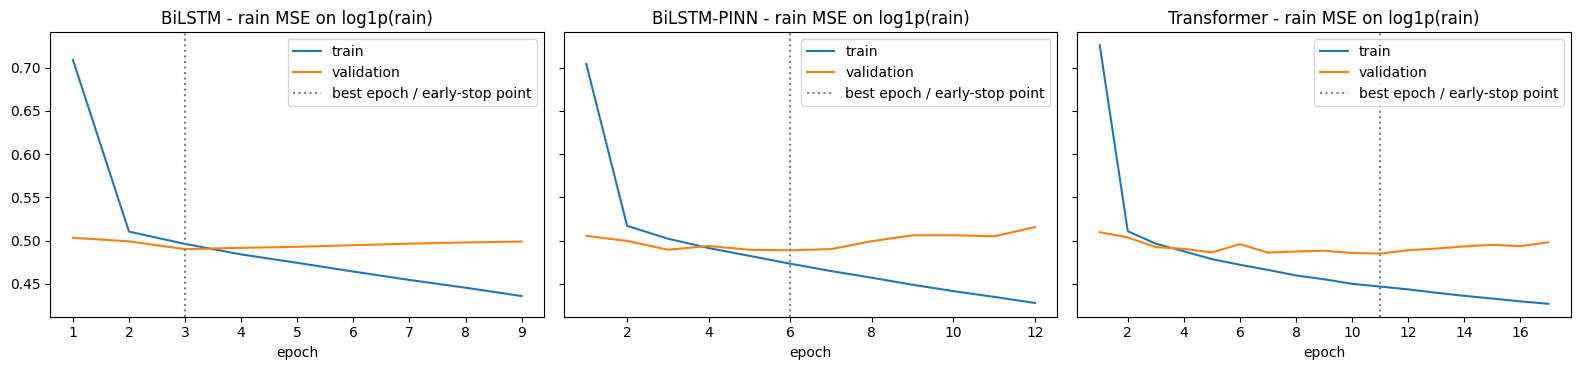

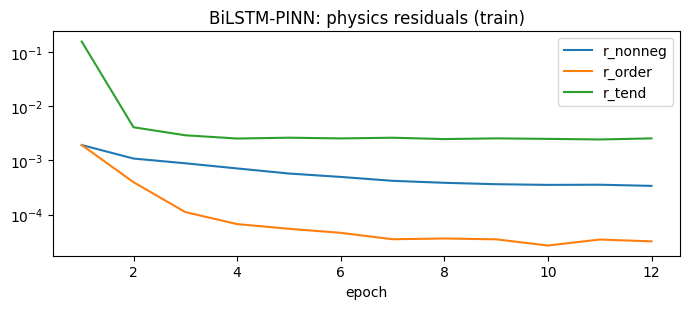

In [19]:
HISTS = [("BiLSTM", hist_bilstm), ("BiLSTM-PINN", hist_bilstm_pinn), ("Transformer", hist_transformer)]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, (nm, h) in zip(axes, HISTS):
    ax.plot(h.index + 1, h["train_loss"], label="train"); ax.plot(h.index + 1, h["val_loss"], label="validation")
    ax.axvline(h["val_loss"].values.argmin() + 1, color="gray", ls=":", label="best epoch / early-stop point")
    ax.set_title(f"{nm} - rain MSE on log1p(rain)"); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()

# physics terms of the PINN over epochs
fig, ax = plt.subplots(figsize=(7, 3.2))
for k in ["train_r_nonneg", "train_r_order", "train_r_tend"]:
    ax.plot(hist_bilstm_pinn.index + 1, hist_bilstm_pinn[k], label=k.replace("train_", ""))
ax.set_yscale("symlog", linthresh=1e-6); ax.set_title("BiLSTM-PINN: physics residuals (train)"); ax.set_xlabel("epoch"); ax.legend(); plt.tight_layout(); plt.show()

In [20]:
@torch.no_grad()
def predict_mm(model, loader, return_raw=False):
    model.eval()
    outs = []
    for xb, _, _ in loader:
        o = model(xb).float()
        outs.append((o[:, 0] if o.ndim == 2 else o).cpu())         # rain is always output 0 (the PINN has 5 extra outputs)
    raw_log = torch.cat(outs).numpy()
    mm = np.clip(np.expm1(raw_log), 0, None)
    return (mm, raw_log) if return_raw else mm

predictions["BiLSTM"]      = {s: predict_mm(bilstm,      loaders[s]) for s in ["val", "test"]}
predictions["BiLSTM-PINN"] = {s: predict_mm(bilstm_pinn, loaders[s]) for s in ["val", "test"]}
predictions["Transformer"] = {s: predict_mm(transformer, loaders[s]) for s in ["val", "test"]}

# ---- back-transform calibration ----
# The networks minimise MSE on log1p(rain); expm1 of that prediction is a (conditional) MEDIAN-like value and under-predicts the mean
# in mm (v2 bias ~ -2 mm). One scalar per model, fitted on VALIDATION only, removes most of it.
CAL = {}
for k in ["BiLSTM", "BiLSTM-PINN", "Transformer"]:
    a = float(np.sum(y_mm["val"] * predictions[k]["val"]) / np.sum(predictions[k]["val"] ** 2))
    CAL[k] = a
    predictions[k + " (cal)"] = {s: predictions[k][s] * a for s in ["val", "test"]}
print("mm-calibration factors (fitted on validation):", {k: round(v, 2) for k, v in CAL.items()})

results = pd.concat([evaluate(k, v) for k, v in predictions.items()])
results.index.names = ["split", "model"]
results = results.loc[["val", "test"]]
results.to_csv(os.path.join(ARTIFACT_DIR, "results.csv"))
print("Higher is better: R2, PCC, SCC, AUC, F1.   Lower is better: RMSE, MAE, RMSE_log, |Bias|.")
display(results.round(3))

print("\nFINAL TEST SET - main metrics")
display(results.loc["test", ["RMSE", "R2", "PCC", "SCC"]].round(4).sort_values("RMSE"))

# physics sanity check: how often does each network output a physically impossible (negative) rain amount BEFORE clipping?
for nm, mdl in [("BiLSTM", bilstm), ("BiLSTM-PINN", bilstm_pinn), ("Transformer", transformer)]:
    _, raw_log = predict_mm(mdl, loaders["test"], return_raw=True)
    print(f"{nm:12s} test: share of raw outputs with log1p(rain) < 0 (negative rain): {100*(raw_log < 0).mean():.2f} %")

mm-calibration factors (fitted on validation): {'BiLSTM': 1.63, 'BiLSTM-PINN': 1.89, 'Transformer': 1.66}
Higher is better: R2, PCC, SCC, AUC, F1.   Lower is better: RMSE, MAE, RMSE_log, |Bias|.


RMSE     R2    PCC    SCC    MAE   Bias  RMSE_log  AUC(rain)  F1(rain)  Precision  Recall
split model                                                                                                         
val   Climatology        10.281  0.151  0.406  0.576  4.655  0.709     1.133      0.822     0.658      0.588   0.746
      Persistence        11.187 -0.006  0.497  0.688  3.723  0.004     0.872      0.856     0.727      0.676   0.786
      GBM (reference)     9.486  0.277  0.592  0.741  2.936 -1.794     0.698      0.916     0.763      0.708   0.828
      BiLSTM              9.392  0.291  0.602  0.740  2.946 -1.586     0.700      0.915     0.764      0.713   0.824
      BiLSTM-PINN         9.611  0.258  0.603  0.736  2.947 -1.879     0.699      0.914     0.764      0.710   0.826
      Transformer         9.410  0.288  0.605  0.741  2.895 -1.762     0.696      0.916     0.765      0.722   0.813
      BiLSTM (cal)        8.914  0.361  0.602  0.740  3.189 -0.238     0.756      0.915     0.764      0.713   0.824
      BiLSTM-PINN (cal)   8.906  0.363  0.603  0.736  3.178 -0.231     0.758      0.914     0.764      0.710   0.826
      Transformer (cal)   8.898  0.364  0.605  0.741  3.070 -0.456     0.732      0.916     0.765      0.722   0.813
test  Climatology        11.588  0.230  0.480  0.658  5.224  0.058     1.094      0.856     0.731      0.672   0.802
      Persistence        12.871  0.050  0.522  0.722  4.759 -0.020     0.936      0.868     0.773      0.731   0.821
      GBM (reference)    11.032  0.302  0.609  0.786  3.777 -2.271     0.742      0.927     0.809      0.749   0.881
      BiLSTM             11.051  0.300  0.606  0.784  3.796 -2.117     0.745      0.926     0.809      0.751   0.877
      BiLSTM-PINN        11.334  0.263  0.609  0.783  3.836 -2.514     0.747      0.926     0.809      0.748   0.882
      Transformer        11.203  0.280  0.606  0.785  3.807 -2.461     0.750      0.927     0.811      0.763   0.866
      BiLSTM (cal)       10.521  0.365  0.606  0.784  4.072 -0.280     0.799      0.926     0.809      0.751   0.877
      BiLSTM-PINN (cal)  10.491  0.369  0.609  0.783  4.070 -0.266     0.805      0.926     0.809      0.748   0.882
      Transformer (cal)  10.529  0.364  0.606  0.785  3.940 -0.751     0.774      0.927     0.811      0.763   0.866


FINAL TEST SET - main metrics


,RMSE,R2,PCC,SCC
model,,,,
BiLSTM-PINN (cal),10.4910,0.3688,0.6087,0.7833
BiLSTM (cal),10.5211,0.3652,0.6064,0.7838
Transformer (cal),10.5292,0.3642,0.6065,0.7849
GBM (reference),11.0318,0.3021,0.6087,0.7858
BiLSTM,11.0507,0.2997,0.6064,0.7838
Transformer,11.2027,0.2803,0.6065,0.7849
BiLSTM-PINN,11.3344,0.2632,0.6087,0.7833
Climatology,11.5877,0.2299,0.4797,0.6579
Persistence,12.8706,0.0500,0.5220,0.7220


BiLSTM       test: share of raw outputs with log1p(rain) < 0 (negative rain): 3.00 %
BiLSTM-PINN  test: share of raw outputs with log1p(rain) < 0 (negative rain): 9.10 %
Transformer  test: share of raw outputs with log1p(rain) < 0 (negative rain): 14.44 %


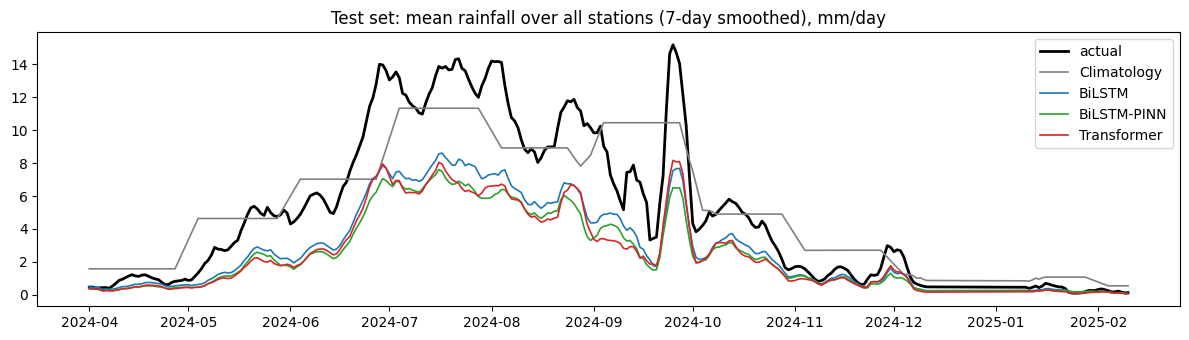

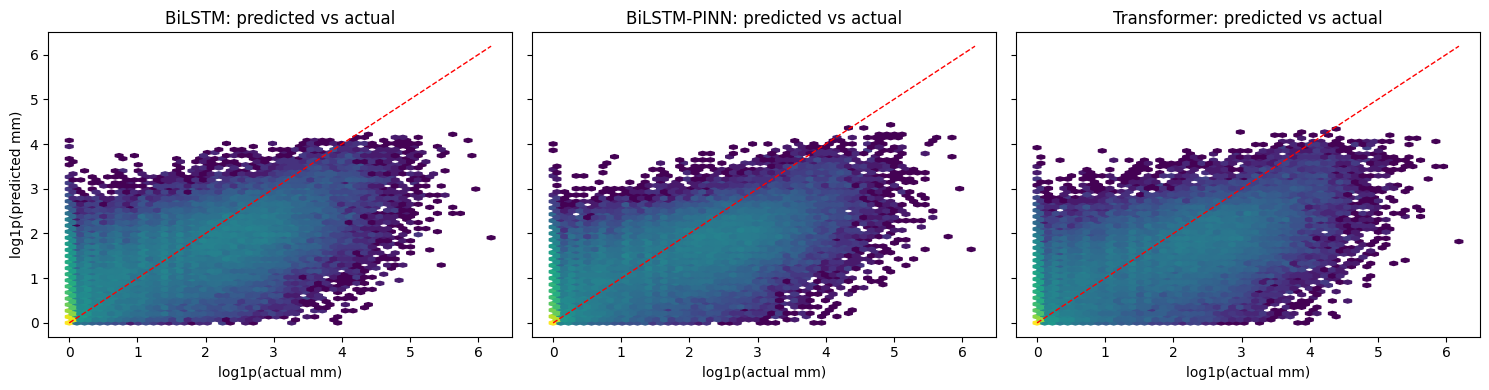

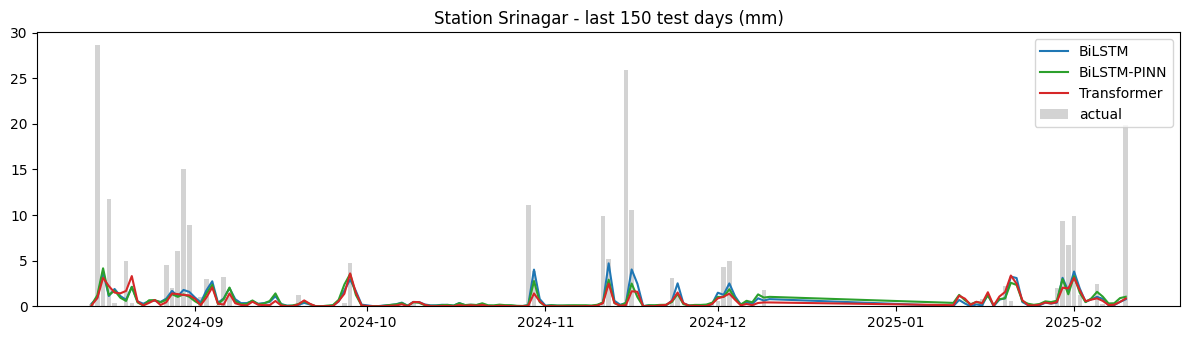

In [21]:
# ---- plots on the FINAL TEST set ----
tt = tgt_idx["test"]
res = pd.DataFrame({"date": dates[tt], "station_id": sid[tt], "actual": y_mm["test"],
                    **{k: predictions[k]["test"] for k in predictions}})
res.to_csv(os.path.join(ARTIFACT_DIR, "test_predictions.csv"), index=False)

# (a) all-station daily average
daily_avg = res.groupby("date")[["actual", "Climatology", "BiLSTM", "BiLSTM-PINN", "Transformer"]].mean().rolling(7, center=True, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(daily_avg.index, daily_avg["actual"], "k", lw=2, label="actual")
for k, c in [("Climatology", "gray"), ("BiLSTM", "tab:blue"), ("BiLSTM-PINN", "tab:green"), ("Transformer", "tab:red")]:
    ax.plot(daily_avg.index, daily_avg[k], c, lw=1.2, label=k)
ax.set_title("Test set: mean rainfall over all stations (7-day smoothed), mm/day"); ax.legend(); plt.tight_layout(); plt.show()

# (b) predicted vs actual (log scale density)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
for ax, k in zip(axes, ["BiLSTM", "BiLSTM-PINN", "Transformer"]):
    hb = ax.hexbin(np.log1p(res["actual"]), np.log1p(res[k]), gridsize=55, bins="log", mincnt=1, cmap="viridis")
    lim = [0, np.log1p(res["actual"].max())]; ax.plot(lim, lim, "r--", lw=1)
    ax.set_title(f"{k}: predicted vs actual"); ax.set_xlabel("log1p(actual mm)")
axes[0].set_ylabel("log1p(predicted mm)"); plt.tight_layout(); plt.show()

# (c) one station, last 150 test days
best_station = res.groupby("station_id")["actual"].count().idxmax()
r1 = res[res["station_id"] == best_station].sort_values("date").tail(150)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(r1["date"], r1["actual"], color="lightgray", label="actual")
ax.plot(r1["date"], r1["BiLSTM"], "tab:blue", label="BiLSTM"); ax.plot(r1["date"], r1["BiLSTM-PINN"], "tab:green", label="BiLSTM-PINN"); ax.plot(r1["date"], r1["Transformer"], "tab:red", label="Transformer")
ax.set_title(f"Station {best_station.split('|')[0]} - last 150 test days (mm)"); ax.legend(); plt.tight_layout(); plt.show()

In [22]:
# ============ 9.0 shared setup for the analysis section ============
from mpl_toolkits.mplot3d import Axes3D            # noqa: F401  (registers the '3d' projection)
from matplotlib.patches import Patch
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score, confusion_matrix

REF_MODELS = [m for m in ["Climatology", "Persistence", "GBM (reference)"] if m in res.columns]
NN_MODELS  = ["BiLSTM (cal)", "BiLSTM-PINN (cal)", "Transformer (cal)"]
ALL_MODELS = REF_MODELS + NN_MODELS
MAIN       = [m for m in ALL_MODELS if m not in ("Climatology", "Persistence")]       # GBM + the three networks
MCOL = {"Climatology": "gray", "Persistence": "tab:brown", "GBM (reference)": "tab:purple",
        "BiLSTM (cal)": "tab:blue", "BiLSTM-PINN (cal)": "tab:green", "Transformer (cal)": "tab:red"}
short = lambda k: k.replace(" (cal)", "").replace(" (reference)", "")

R = res.copy()
R["date"]  = pd.to_datetime(R["date"])
R["month"] = R["date"].dt.month
_ll = stations.reindex(R["station_id"].values)
R["lat"], R["lon"] = _ll["latitude"].values, _ll["longitude"].values
y = R["actual"].values

BEST_NN = min(NN_MODELS, key=lambda k: float(np.sqrt(np.mean((R[k] - R["actual"]) ** 2))))
NN_OBJ  = {"BiLSTM (cal)": bilstm, "BiLSTM-PINN (cal)": bilstm_pinn, "Transformer (cal)": transformer}

def save_show(name):
    plt.savefig(os.path.join(ARTIFACT_DIR, f"{name}.png"), dpi=150, bbox_inches="tight"); plt.show()

print(f"{len(R):,} test predictions | {R['station_id'].nunique()} stations | {R['date'].min().date()} -> {R['date'].max().date()}")
print("best network on test RMSE (used for the single-model plots):", BEST_NN)

101,540 test predictions | 412 stations | 2024-04-01 -> 2025-02-10
best network on test RMSE (used for the single-model plots): BiLSTM-PINN (cal)


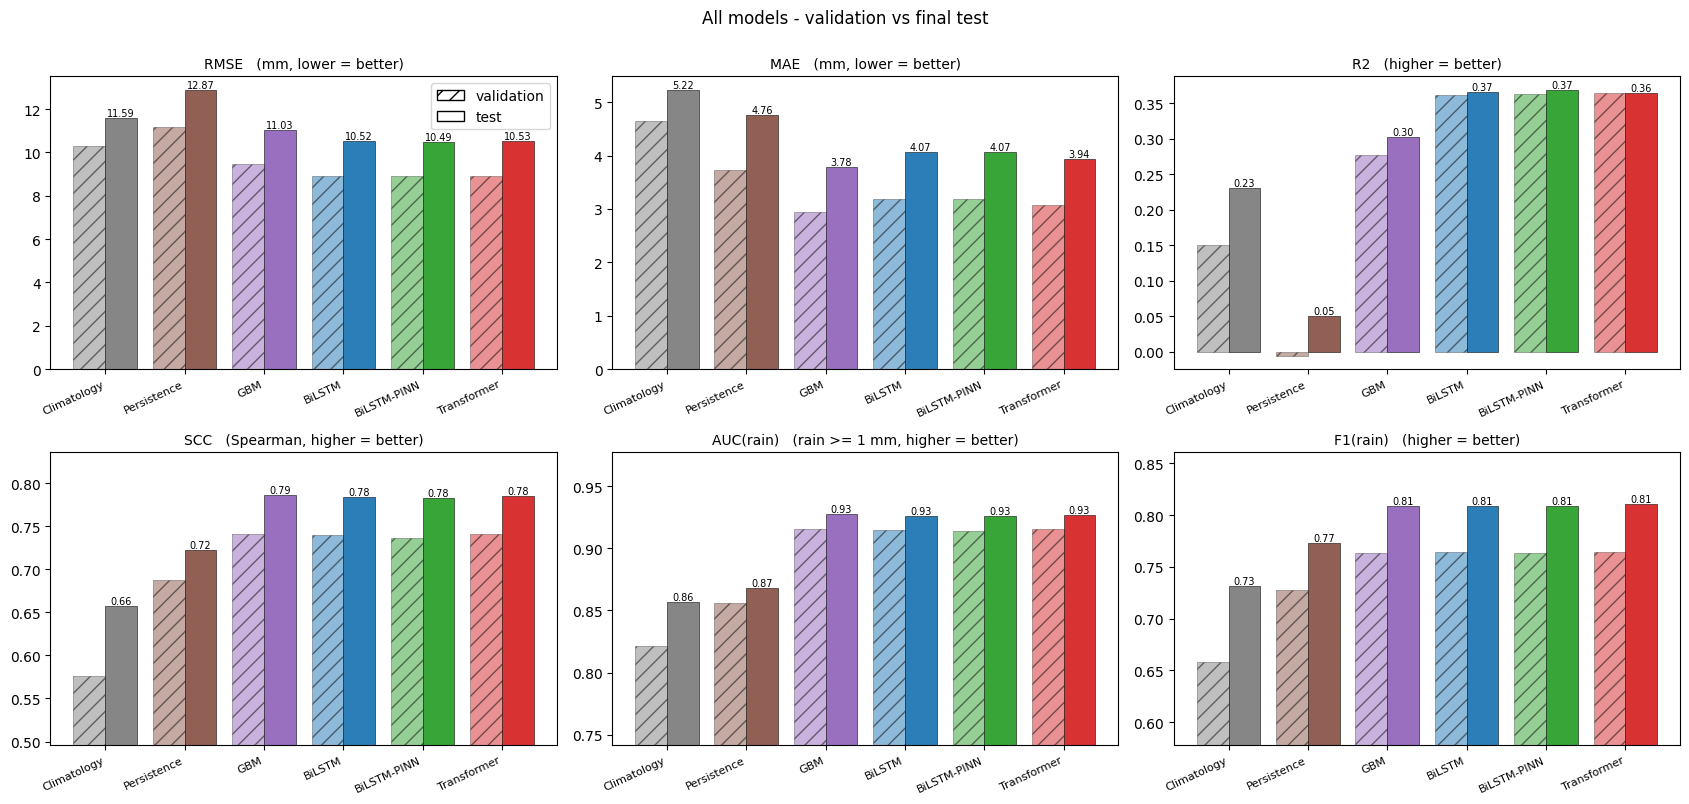

Skill score in %  (0 = same as the reference, >0 = better, <0 = worse):


RMSE skill vs Climatology (%)  RMSE skill vs Persistence (%)  MAE skill vs Climatology (%)  MAE skill vs Persistence (%)
val  Climatology                                  0.0                            8.1                           0.0                         -25.0
     Persistence                                 -8.8                            0.0                          20.0                           0.0
     GBM (reference)                              7.7                           15.2                          36.9                          21.2
     BiLSTM (cal)                                13.3                           20.3                          31.5                          14.3
     BiLSTM-PINN (cal)                           13.4                           20.4                          31.7                          14.6
     Transformer (cal)                           13.5                           20.5                          34.0                          17.5
test Climatology                                  0.0                           10.0                           0.0                          -9.8
     Persistence                                -11.1                            0.0                           8.9                           0.0
     GBM (reference)                              4.8                           14.3                          27.7                          20.6
     BiLSTM (cal)                                 9.2                           18.3                          22.1                          14.4
     BiLSTM-PINN (cal)                            9.5                           18.5                          22.1                          14.5
     Transformer (cal)                            9.1                           18.2                          24.6                          17.2

In [23]:
panels = [("RMSE", "mm, lower = better"), ("MAE", "mm, lower = better"), ("R2", "higher = better"),
          ("SCC", "Spearman, higher = better"), ("AUC(rain)", f"rain >= {RAIN_DAY_MM:g} mm, higher = better"), ("F1(rain)", "higher = better")]
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
x, w = np.arange(len(ALL_MODELS)), 0.4
for ax, (m, sub) in zip(axes.ravel(), panels):
    allv = []
    for off, split in [(-w / 2, "val"), (w / 2, "test")]:
        v = np.array([results.loc[(split, k), m] for k in ALL_MODELS], dtype=float); allv += list(v)
        ax.bar(x + off, v, w, color=[MCOL[k] for k in ALL_MODELS], alpha=0.5 if split == "val" else 0.95,
               edgecolor="k", lw=0.4, hatch="//" if split == "val" else None)
        if split == "test":
            for xi, vi in zip(x + off, v): ax.text(xi, vi, f"{vi:.2f}", ha="center", va="bottom", fontsize=7)
    if m in ("SCC", "AUC(rain)", "F1(rain)"): ax.set_ylim(max(0, min(allv) - 0.08), min(1.0, max(allv) + 0.05))
    ax.set_xticks(x); ax.set_xticklabels([short(k) for k in ALL_MODELS], rotation=25, ha="right", fontsize=8)
    ax.set_title(f"{m}   ({sub})", fontsize=10)
axes[0, 0].legend(handles=[Patch(facecolor="w", edgecolor="k", hatch="//", label="validation"), Patch(facecolor="w", edgecolor="k", label="test")])
fig.suptitle("All models - validation vs final test", y=1.0); plt.tight_layout(); save_show("fig_metric_bars")

# RMSE / MAE skill score:  1 - metric_model / metric_reference   (positive = better than the reference)
rows = {}
for s in ["val", "test"]:
    for k in ALL_MODELS:
        rows[(s, k)] = {f"{m} skill vs {ref} (%)": 100 * (1 - results.loc[(s, k), m] / results.loc[(s, ref), m])
                        for m in ["RMSE", "MAE"] for ref in ["Climatology", "Persistence"]}
print("Skill score in %  (0 = same as the reference, >0 = better, <0 = worse):")
display(pd.DataFrame(rows).T.round(1))

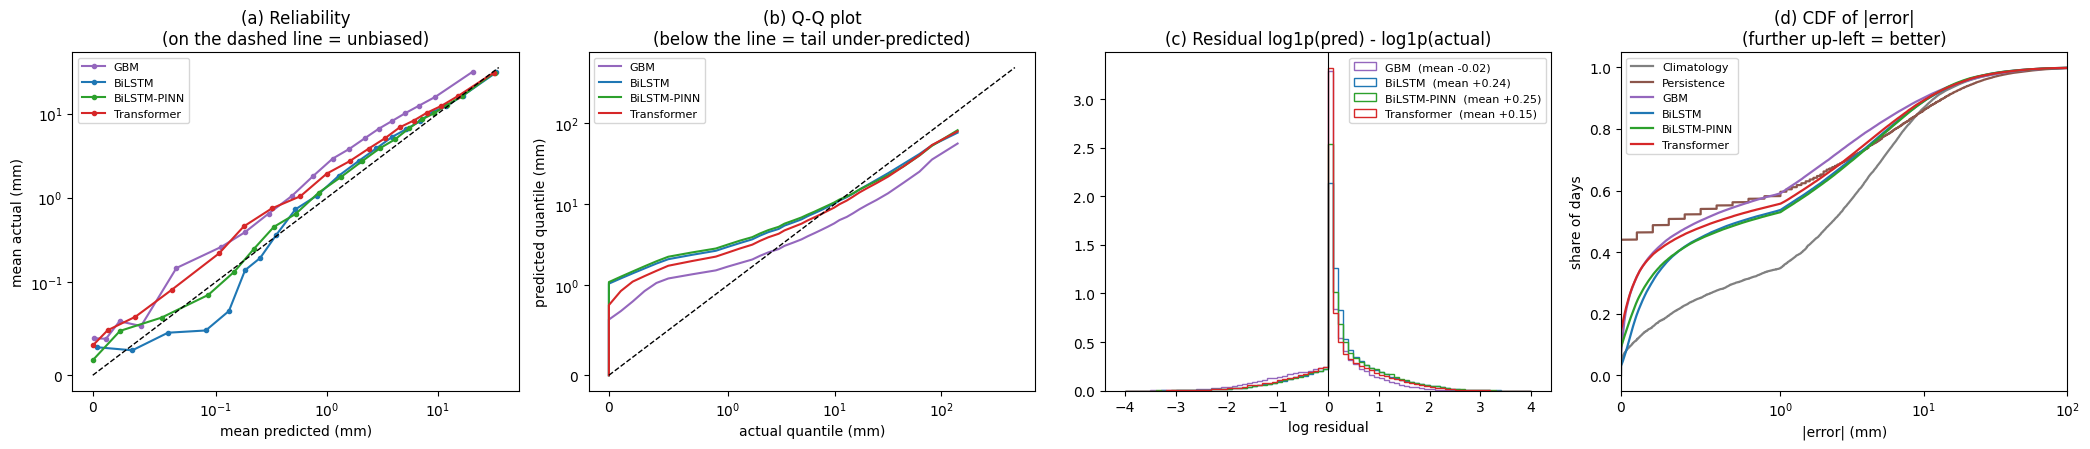

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.6))

# (a) reliability: mean actual rain inside quantile bins of the prediction
ax = axes[0]
for k in MAIN:
    q = pd.qcut(R[k], 20, duplicates="drop")
    g = pd.DataFrame({"p": R[k].values, "a": y, "q": q.values}).groupby("q", observed=True)[["p", "a"]].mean()
    ax.plot(g["p"], g["a"], "o-", ms=3, color=MCOL[k], label=short(k))
hi = max(ax.get_xlim()[1], ax.get_ylim()[1]); ax.plot([0, hi], [0, hi], "k--", lw=1)
ax.set_xscale("symlog", linthresh=0.1); ax.set_yscale("symlog", linthresh=0.1)
ax.set_title("(a) Reliability\n(on the dashed line = unbiased)"); ax.set_xlabel("mean predicted (mm)"); ax.set_ylabel("mean actual (mm)"); ax.legend(fontsize=8)

# (b) Q-Q: do the predictions have the same distribution as the observations?
ax = axes[1]
qs = np.r_[np.linspace(0.01, 0.98, 60), 0.99, 0.995, 0.999]
for k in MAIN: ax.plot(np.quantile(y, qs), np.quantile(R[k].values, qs), color=MCOL[k], label=short(k))
ax.plot([0, y.max()], [0, y.max()], "k--", lw=1)
ax.set_xscale("symlog", linthresh=1); ax.set_yscale("symlog", linthresh=1)
ax.set_title("(b) Q-Q plot\n(below the line = tail under-predicted)"); ax.set_xlabel("actual quantile (mm)"); ax.set_ylabel("predicted quantile (mm)"); ax.legend(fontsize=8)

# (c) residuals on the log scale (the scale the networks are trained on)
ax = axes[2]; bins = np.linspace(-4, 4, 81)
for k in MAIN:
    e = np.log1p(R[k].values) - np.log1p(y)
    ax.hist(np.clip(e, -4, 4), bins=bins, histtype="step", density=True, color=MCOL[k], lw=1.4, label=f"{short(k)}  (mean {e.mean():+.2f})")
ax.axvline(0, color="k", lw=0.8); ax.set_title("(c) Residual log1p(pred) - log1p(actual)"); ax.set_xlabel("log residual"); ax.legend(fontsize=8)

# (d) cumulative distribution of the absolute error
ax = axes[3]
for k in ALL_MODELS:
    ae = np.sort(np.abs(R[k].values - y)); sl = slice(None, None, max(1, len(ae) // 2000))
    ax.plot(ae[sl], (np.arange(1, len(ae) + 1) / len(ae))[sl], color=MCOL[k], lw=1.6, label=short(k))
ax.set_xscale("symlog", linthresh=1); ax.set_xlim(0, 100)
ax.set_title("(d) CDF of |error|\n(further up-left = better)"); ax.set_xlabel("|error| (mm)"); ax.set_ylabel("share of days"); ax.legend(fontsize=8)
plt.tight_layout(); save_show("fig_calibration_residuals")

Number of test days per intensity class:


category,dry <1,light 1-5,moderate 5-20,heavy 20-50,very heavy 50-100,extreme >100
n_days,63404.00,14575.00,16341.00,5595.00,1326.00,299.00
share_pct,62.44,14.35,16.09,5.51,1.31,0.29



Bias (pred - actual, mm) per class:


model,Climatology,Persistence,GBM (reference),BiLSTM (cal),BiLSTM-PINN (cal),Transformer (cal)
category,,,,,,
dry <1,2.57,1.11,0.57,1.10,1.12,0.88
light 1-5,4.54,3.29,0.94,3.50,3.66,2.97
moderate 5-20,-1.41,0.05,-4.51,-0.06,-0.04,-1.06
heavy 20-50,-17.75,-10.01,-19.29,-11.95,-12.31,-13.44
very heavy 50-100,-49.71,-31.64,-48.68,-37.95,-38.74,-39.18
extreme >100,-116.18,-77.15,-114.70,-104.47,-102.26,-103.32


MAE (mm) per class:


model,Climatology,Persistence,GBM (reference),BiLSTM (cal),BiLSTM-PINN (cal),Transformer (cal)
category,,,,,,
dry <1,2.58,1.17,0.59,1.11,1.13,0.90
light 1-5,4.98,5.15,2.30,4.28,4.41,3.93
moderate 5-20,5.49,8.98,6.15,6.47,6.23,6.36
heavy 20-50,18.59,19.37,20.19,16.17,16.14,17.12
very heavy 50-100,49.82,39.77,48.81,39.85,41.01,41.54
extreme >100,116.18,87.61,114.70,104.47,102.53,103.32


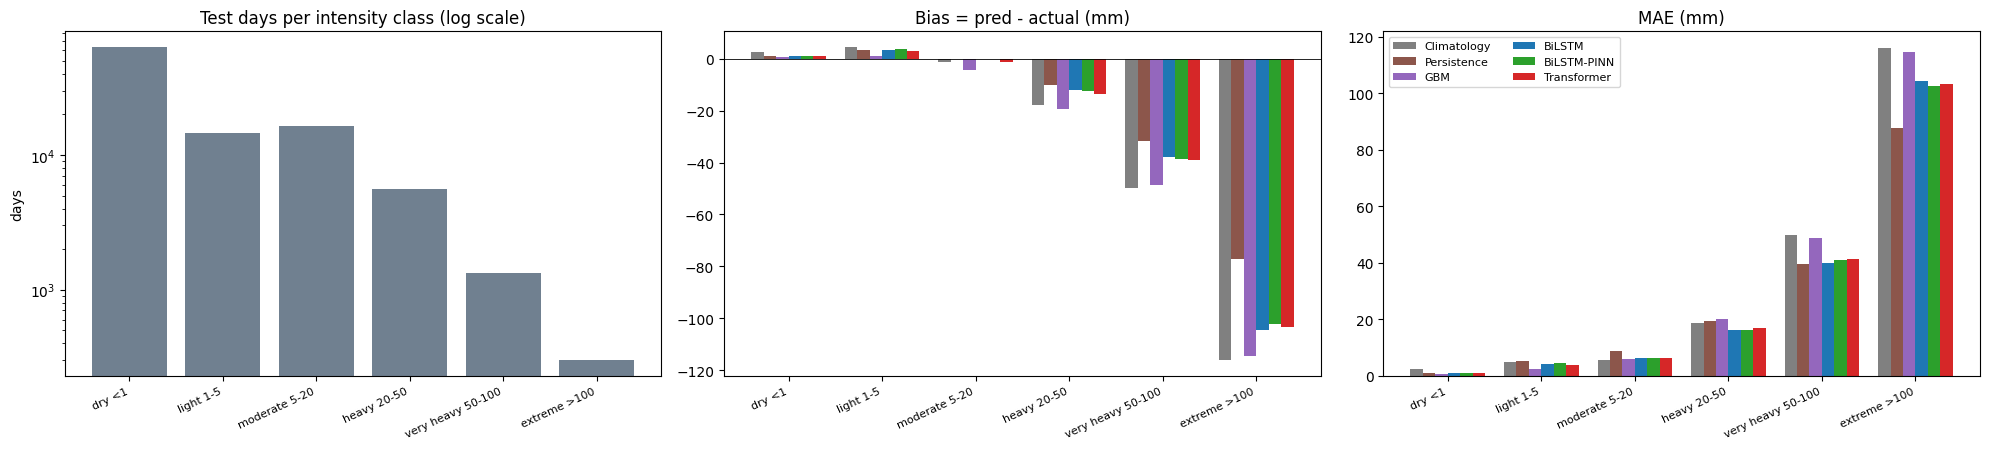

In [25]:
BINS   = [0, 1, 5, 20, 50, 100, np.inf]
LABELS = ["dry <1", "light 1-5", "moderate 5-20", "heavy 20-50", "very heavy 50-100", "extreme >100"]
R["cat"] = pd.cut(R["actual"], BINS, labels=LABELS, right=False)

rows = []
for cat, g in R.groupby("cat", observed=False):
    if len(g) == 0: continue
    for k in ALL_MODELS:
        e = g[k].values - g["actual"].values
        rows.append(dict(category=cat, n=len(g), model=k, MAE=np.abs(e).mean(), Bias=e.mean(), mean_actual=g["actual"].mean(), mean_pred=g[k].mean()))
IT = pd.DataFrame(rows)
cats = [c for c in LABELS if c in set(IT["category"])]
cnt  = IT.drop_duplicates("category").set_index("category")["n"].reindex(cats)
print("Number of test days per intensity class:"); display(cnt.to_frame("n_days").assign(share_pct=(100 * cnt / cnt.sum()).round(2)).T)
print("\nBias (pred - actual, mm) per class:");  display(IT.pivot(index="category", columns="model", values="Bias").reindex(cats)[ALL_MODELS].round(2))
print("MAE (mm) per class:");                    display(IT.pivot(index="category", columns="model", values="MAE").reindex(cats)[ALL_MODELS].round(2))

fig, axes = plt.subplots(1, 3, figsize=(20, 4.6))
axes[0].bar(range(len(cats)), cnt.values, color="slategray"); axes[0].set_yscale("log")
axes[0].set_title("Test days per intensity class (log scale)"); axes[0].set_ylabel("days")
xx, wd = np.arange(len(cats)), 0.8 / len(ALL_MODELS)
for ax, col, ttl in [(axes[1], "Bias", "Bias = pred - actual (mm)"), (axes[2], "MAE", "MAE (mm)")]:
    pv = IT.pivot(index="category", columns="model", values=col).reindex(cats)
    for i, k in enumerate(ALL_MODELS): ax.bar(xx + (i - (len(ALL_MODELS) - 1) / 2) * wd, pv[k].values, wd, color=MCOL[k], label=short(k))
    ax.axhline(0, color="k", lw=0.6); ax.set_title(ttl)
axes[2].legend(fontsize=8, ncol=2)
for ax in axes: ax.set_xticks(xx); ax.set_xticklabels(cats, rotation=25, ha="right", fontsize=8)
plt.tight_layout(); save_show("fig_error_by_intensity")
IT.to_csv(os.path.join(ARTIFACT_DIR, "error_by_intensity.csv"), index=False)


POD on the TEST set  (rows = model, columns = event threshold in mm)


event_mm,1,5,10,25,50
model,,,,,
Climatology,0.807,0.654,0.651,0.420,0.225
Persistence,0.821,0.742,0.655,0.441,0.402
GBM (reference),0.882,0.794,0.706,0.496,0.366
BiLSTM (cal),0.877,0.782,0.677,0.505,0.377
BiLSTM-PINN (cal),0.879,0.792,0.692,0.496,0.339
Transformer (cal),0.866,0.778,0.669,0.509,0.308



FAR on the TEST set  (rows = model, columns = event threshold in mm)


event_mm,1,5,10,25,50
model,,,,,
Climatology,0.330,0.467,0.612,0.750,0.710
Persistence,0.269,0.411,0.522,0.650,0.728
GBM (reference),0.253,0.377,0.489,0.609,0.669
BiLSTM (cal),0.248,0.373,0.473,0.618,0.661
BiLSTM-PINN (cal),0.250,0.376,0.481,0.622,0.640
Transformer (cal),0.238,0.371,0.478,0.638,0.606



CSI on the TEST set  (rows = model, columns = event threshold in mm)


event_mm,1,5,10,25,50
model,,,,,
Climatology,0.577,0.416,0.321,0.186,0.145
Persistence,0.631,0.489,0.382,0.242,0.194
GBM (reference),0.679,0.537,0.421,0.280,0.210
BiLSTM (cal),0.680,0.534,0.421,0.278,0.217
BiLSTM-PINN (cal),0.680,0.536,0.422,0.273,0.212
Transformer (cal),0.682,0.534,0.415,0.269,0.209


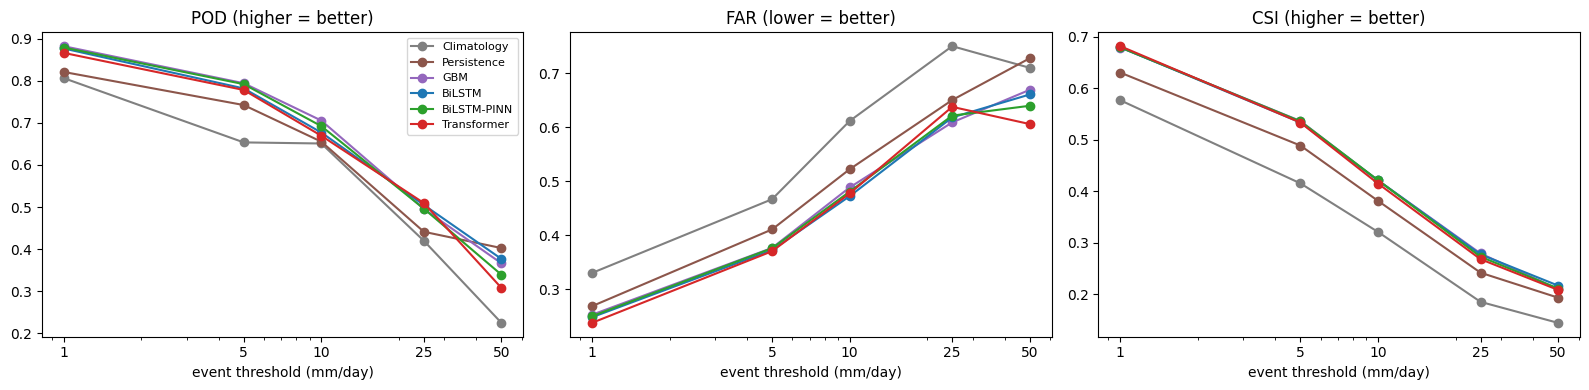

In [26]:
EVENTS = [1, 5, 10, 25, 50]
def _cat_scores(obs, pred, evT, thr):
    ob, pb = obs >= evT, pred >= thr
    hit, miss, fa = (ob & pb).sum(), (ob & ~pb).sum(), (~ob & pb).sum()
    return hit / max(hit + miss, 1), fa / max(hit + fa, 1), hit / max(hit + miss + fa, 1)      # POD, FAR, CSI

rows = []
for k in ALL_MODELS:
    pv, pt = predictions[k]["val"], predictions[k]["test"]
    cand = np.unique(np.quantile(pv, np.linspace(0.40, 0.999, 80)))
    for evT in EVENTS:
        if (y_mm["val"] >= evT).sum() < 20 or (y_mm["test"] >= evT).sum() < 20: continue
        thr = max(cand, key=lambda t: _cat_scores(y_mm["val"], pv, evT, t)[2])
        pod, far, csi = _cat_scores(y_mm["test"], pt, evT, thr)
        rows.append(dict(model=k, event_mm=evT, n_events=int((y_mm["test"] >= evT).sum()), POD=pod, FAR=far, CSI=csi))
EV = pd.DataFrame(rows); EV.to_csv(os.path.join(ARTIFACT_DIR, "event_scores.csv"), index=False)
for m in ["POD", "FAR", "CSI"]:
    print(f"\n{m} on the TEST set  (rows = model, columns = event threshold in mm)"); display(EV.pivot(index="model", columns="event_mm", values=m).reindex(ALL_MODELS).round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, m, ttl in zip(axes, ["POD", "FAR", "CSI"], ["POD (higher = better)", "FAR (lower = better)", "CSI (higher = better)"]):
    for k in ALL_MODELS:
        d = EV[EV["model"] == k]; ax.plot(d["event_mm"], d[m], "o-", color=MCOL[k], label=short(k))
    ax.set_xscale("log"); ax.set_xticks(sorted(EV["event_mm"].unique())); ax.set_xticklabels(sorted(EV["event_mm"].unique()))
    ax.set_xlabel("event threshold (mm/day)"); ax.set_title(ttl)
axes[0].legend(fontsize=8); plt.tight_layout(); save_show("fig_event_detection")

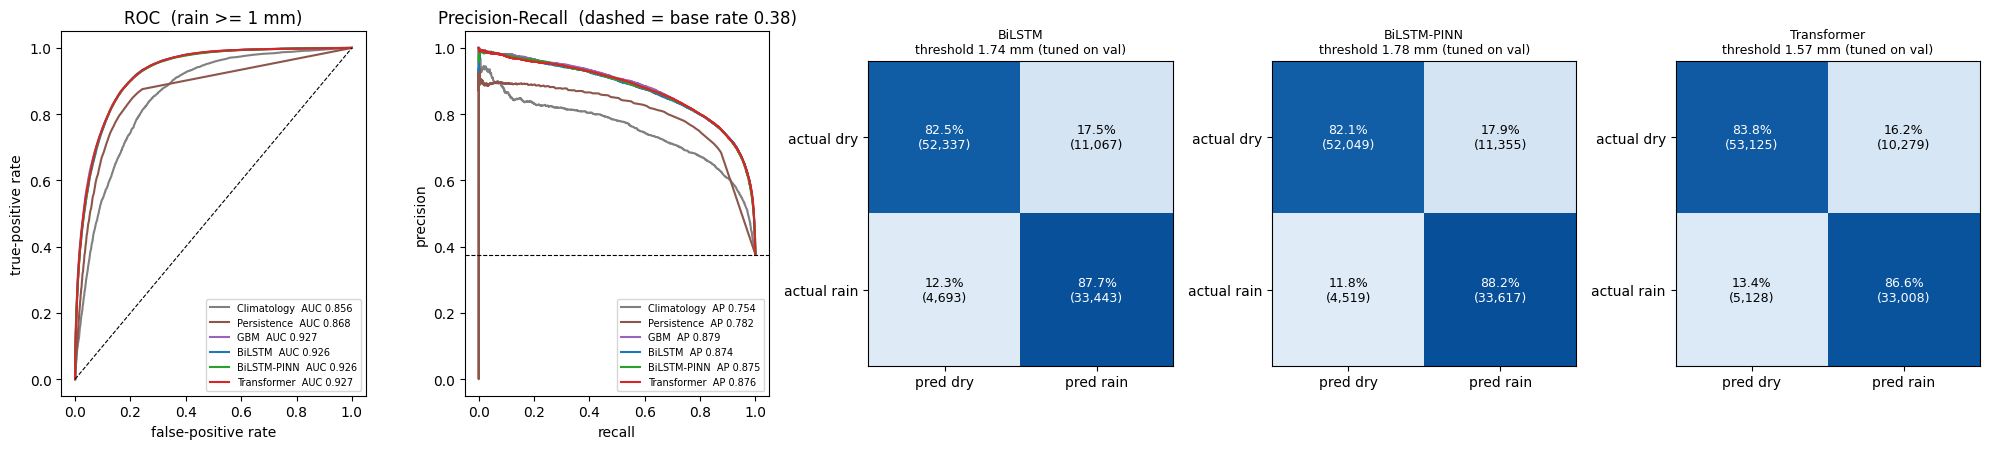

In [27]:
y_rain = y >= RAIN_DAY_MM
fig = plt.figure(figsize=(20, 4.6))
gs  = fig.add_gridspec(1, 2 + len(NN_MODELS))
ax = fig.add_subplot(gs[0, 0])
for k in ALL_MODELS:
    fpr, tpr, _ = roc_curve(y_rain, R[k].values); ax.plot(fpr, tpr, color=MCOL[k], label=f"{short(k)}  AUC {results.loc[('test', k), 'AUC(rain)']:.3f}")
ax.plot([0, 1], [0, 1], "k--", lw=0.8); ax.set_title(f"ROC  (rain >= {RAIN_DAY_MM:g} mm)"); ax.set_xlabel("false-positive rate"); ax.set_ylabel("true-positive rate"); ax.legend(fontsize=7)
ax = fig.add_subplot(gs[0, 1])
for k in ALL_MODELS:
    pr, rc, _ = precision_recall_curve(y_rain, R[k].values); ax.plot(rc, pr, color=MCOL[k], label=f"{short(k)}  AP {average_precision_score(y_rain, R[k].values):.3f}")
ax.axhline(y_rain.mean(), color="k", ls="--", lw=0.8); ax.set_title(f"Precision-Recall  (dashed = base rate {y_rain.mean():.2f})"); ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.legend(fontsize=7)
for i, k in enumerate(NN_MODELS):
    thr = best_threshold(y_mm["val"] >= RAIN_DAY_MM, predictions[k]["val"])        # threshold chosen on VALIDATION
    cmx = confusion_matrix(y_rain, R[k].values >= thr); cmn = cmx / cmx.sum(axis=1, keepdims=True)
    ax = fig.add_subplot(gs[0, 2 + i]); ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for a in range(2):
        for b in range(2): ax.text(b, a, f"{100 * cmn[a, b]:.1f}%\n({cmx[a, b]:,})", ha="center", va="center", color="w" if cmn[a, b] > 0.5 else "k", fontsize=9)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["pred dry", "pred rain"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["actual dry", "actual rain"])
    ax.set_title(f"{short(k)}\nthreshold {thr:.2f} mm (tuned on val)", fontsize=9)
plt.tight_layout(); save_show("fig_classification")

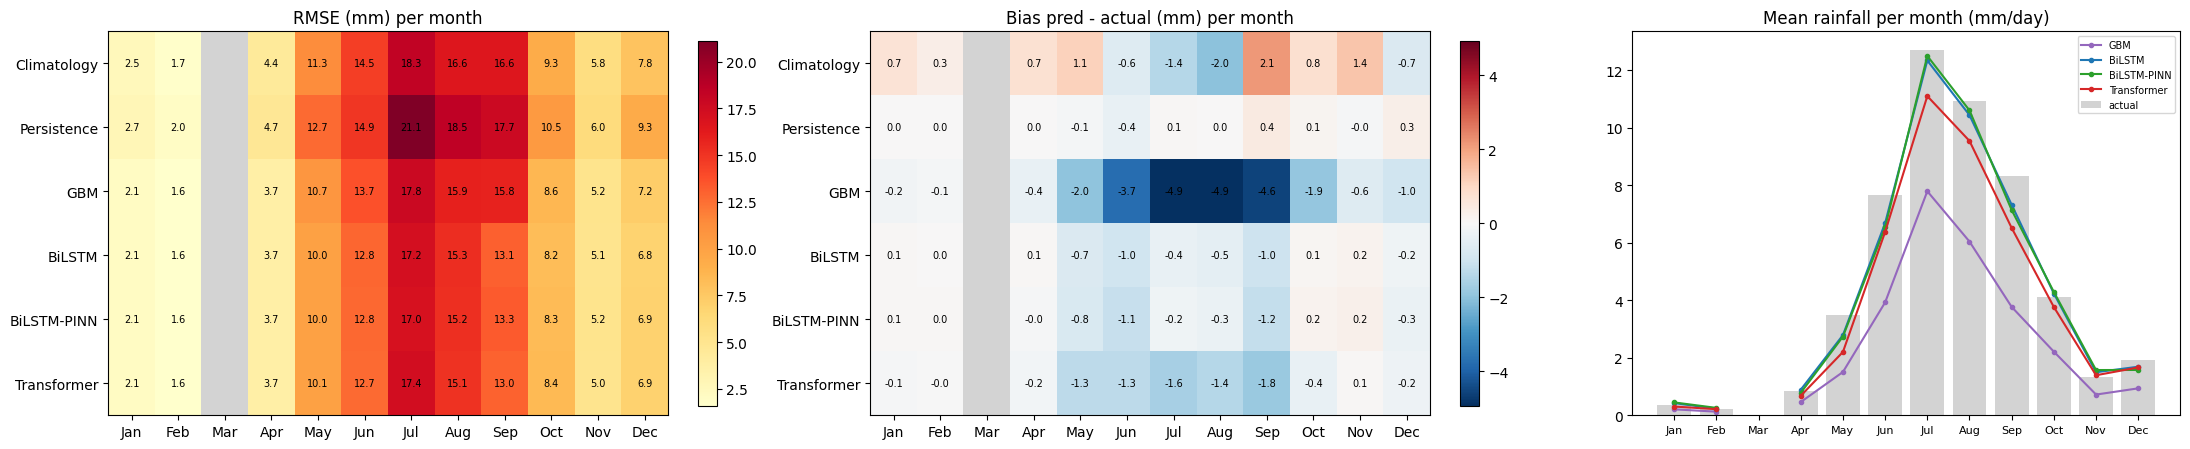

days  mean_actual   RMSE   MAE  Bias
monsoon (Jun-Sep) Climatology        36786.0        10.43  16.56  9.10 -1.29
                  Persistence        36786.0        10.43  18.36  9.23 -0.09
                  GBM (reference)    36786.0        10.43  15.92  7.40 -4.52
                  BiLSTM (cal)       36786.0        10.43  15.20  7.83 -0.63
                  BiLSTM-PINN (cal)  36786.0        10.43  15.09  7.82 -0.57
                  Transformer (cal)  36786.0        10.43  15.17  7.66 -1.44
rest of year      Climatology        64754.0         1.99   7.40  3.02  0.83
                  Persistence        64754.0         1.99   8.27  2.22  0.02
                  GBM (reference)    64754.0         1.99   6.85  1.72 -1.00
                  BiLSTM (cal)       64754.0         1.99   6.51  1.94 -0.08
                  BiLSTM-PINN (cal)  64754.0         1.99   6.57  1.94 -0.09
                  Transformer (cal)  64754.0         1.99   6.57  1.83 -0.36

In [28]:
months = np.arange(1, 13)
def by_month(fn):
    out = pd.DataFrame(np.nan, index=months, columns=ALL_MODELS)
    for mth, g in R.groupby("month"):
        for k in ALL_MODELS: out.loc[mth, k] = fn(g["actual"].values, g[k].values)
    return out
rmse_m = by_month(lambda a, p: np.sqrt(np.mean((p - a) ** 2)))
bias_m = by_month(lambda a, p: np.mean(p - a))
mean_a = R.groupby("month")["actual"].mean().reindex(months)
mean_p = pd.DataFrame({k: R.groupby("month")[k].mean().reindex(months) for k in MAIN})

MN = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, axes = plt.subplots(1, 3, figsize=(22, 4.6), gridspec_kw=dict(width_ratios=[1, 1, 0.9]))
for ax, Mx, ttl, cmap, sym in [(axes[0], rmse_m, "RMSE (mm) per month", "YlOrRd", False), (axes[1], bias_m, "Bias pred - actual (mm) per month", "RdBu_r", True)]:
    A = np.ma.masked_invalid(Mx.T.values); cm_ = plt.get_cmap(cmap).copy(); cm_.set_bad("lightgray")
    vmax = np.nanmax(np.abs(Mx.values)) if sym else None
    im = ax.imshow(A, aspect="auto", cmap=cm_, vmin=-vmax if sym else None, vmax=vmax)
    for i in range(A.shape[0]):
        for jj in range(A.shape[1]):
            if not np.ma.is_masked(A[i, jj]): ax.text(jj, i, f"{A[i, jj]:.1f}", ha="center", va="center", fontsize=7)
    ax.set_xticks(range(12)); ax.set_xticklabels(MN); ax.set_yticks(range(len(ALL_MODELS))); ax.set_yticklabels([short(k) for k in ALL_MODELS]); ax.set_title(ttl)
    plt.colorbar(im, ax=ax, fraction=0.03)
ax = axes[2]; ax.bar(months, mean_a.values, color="lightgray", label="actual")
for k in MAIN: ax.plot(months, mean_p[k].values, "o-", ms=3, color=MCOL[k], label=short(k))
ax.set_xticks(months); ax.set_xticklabels(MN, fontsize=8); ax.set_title("Mean rainfall per month (mm/day)"); ax.legend(fontsize=7)
plt.tight_layout(); save_show("fig_monthly")

mons = R["month"].isin([6, 7, 8, 9]).values
ms_tab = {}
for nm, msk in [("monsoon (Jun-Sep)", mons), ("rest of year", ~mons)]:
    for k in ALL_MODELS:
        e = R[k].values[msk] - y[msk]
        ms_tab[(nm, k)] = {"days": int(msk.sum()), "mean_actual": y[msk].mean(), "RMSE": np.sqrt(np.mean(e ** 2)), "MAE": np.abs(e).mean(), "Bias": e.mean()}
display(pd.DataFrame(ms_tab).T.round(2))

BiLSTM-PINN: 412 stations with >= 30 test days
  beats climatology (RMSE) at 95% of stations | beats persistence at 95% of stations
  median per-station correlation 0.59 | median RMSE 7.92 mm | median |bias| 0.55 mm

10 best stations by RMSE:


,name,n,mean_actual,RMSE,Bias,corr,skill_vs_clim
sid,,,,,,,
Bhatinda|30.1667|74.5833|207,Bhatinda,246,0.98,3.20,0.29,0.54,43.64
Mahabubnagar|16.75|78.0|504,Mahabubnagar,246,2.98,3.71,0.41,0.70,11.10
Shimla / Kanda|31.0818|77.068|1546,Shimla / Kanda,244,2.22,3.93,0.79,0.64,18.40
Nasik|20.0|73.7833|598,Nasik,246,3.15,4.08,0.65,0.77,16.12
Poona / Lohogaon Aerodrome|18.5833|73.9167|589,Poona / Lohogaon Aerodrome,246,2.71,4.14,0.65,0.70,7.38
Koppal|15.35|76.15|532,Koppal,246,3.34,4.26,0.22,0.67,16.19
Ludhiana / Dor?ha|30.8547|75.9526|254,Ludhiana / Dor?ha,246,1.52,4.39,0.16,0.49,6.56
Pilani|28.3333|75.5833|300,Pilani,246,1.99,4.43,-0.19,0.67,20.76
Chapra|25.7833|84.7333|55,Chapra,244,2.84,4.44,0.60,0.75,27.28


10 worst stations by RMSE:


,name,n,mean_actual,RMSE,Bias,corr,skill_vs_clim
sid,,,,,,,
Goalpara|26.1833|90.6333|36,Goalpara,246,14.71,24.08,-3.89,0.73,15.17
Ratnagiri|16.9833|73.3333|75,Ratnagiri,246,14.24,24.11,-2.92,0.65,5.25
Agartala|23.8833|91.25|15,Agartala,244,8.40,24.22,-3.53,0.49,7.29
Karwar|14.7833|74.1333|3,Karwar,246,14.28,24.99,-4.81,0.65,6.83
Rajkot|22.3|70.7833|134,Rajkot,244,5.58,25.47,-3.31,0.50,6.01
Honavar|14.2833|74.45|8,Honavar,246,18.76,25.92,-5.43,0.72,13.63
Mahabaleshwar|17.9333|73.6667|1384,Mahabaleshwar,246,22.22,28.03,-2.03,0.80,16.39
Dhubri Rupsi|26.15|89.9167|35,Dhubri Rupsi,246,15.59,28.14,-4.18,0.68,8.78
Porbandar|21.65|69.6667|5,Porbandar,246,5.25,31.72,-3.07,0.26,0.58


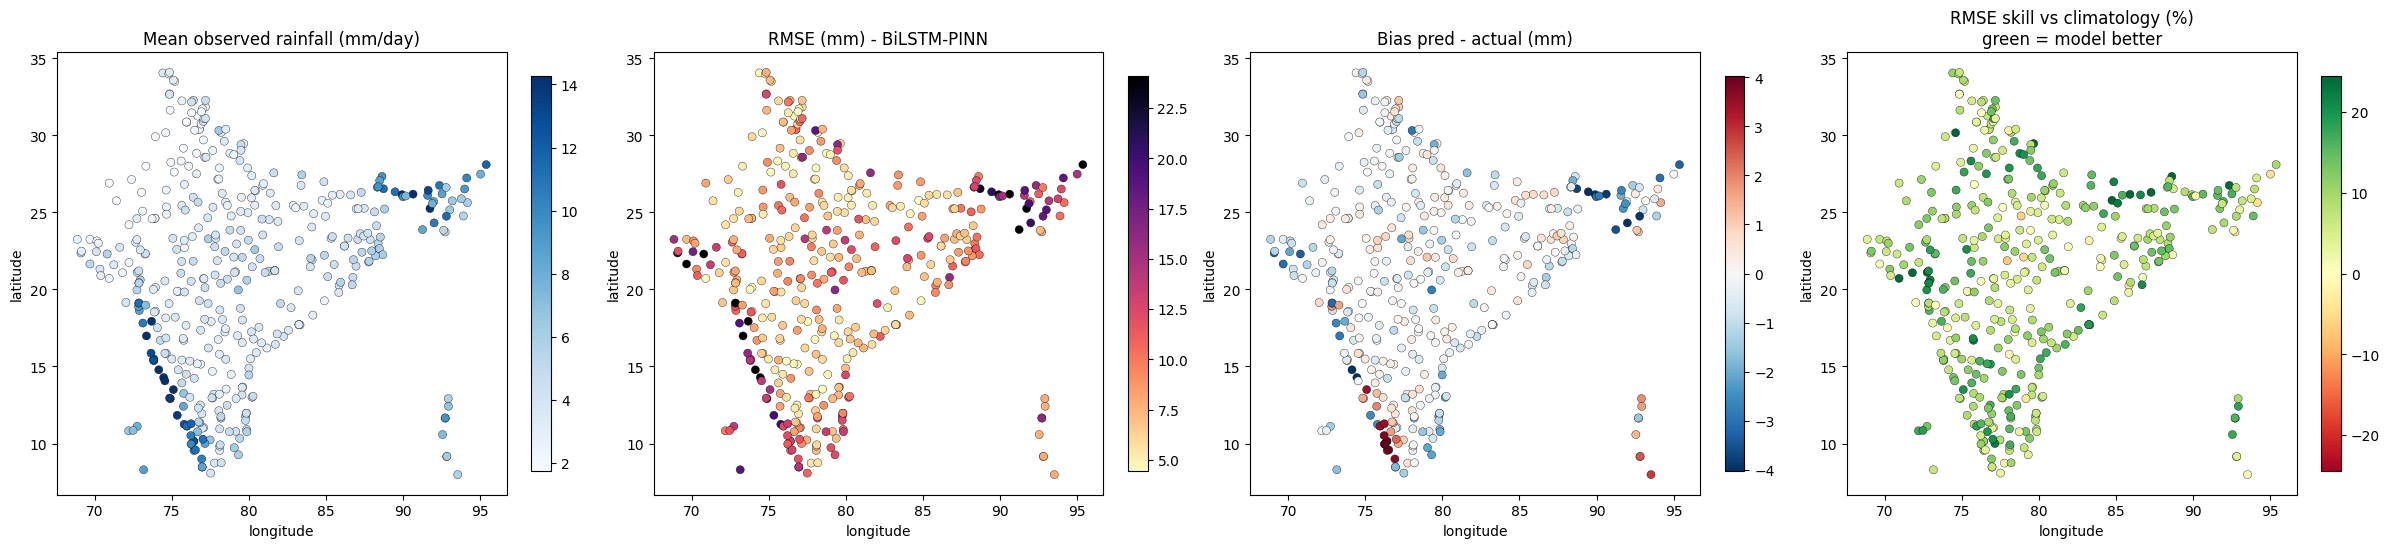

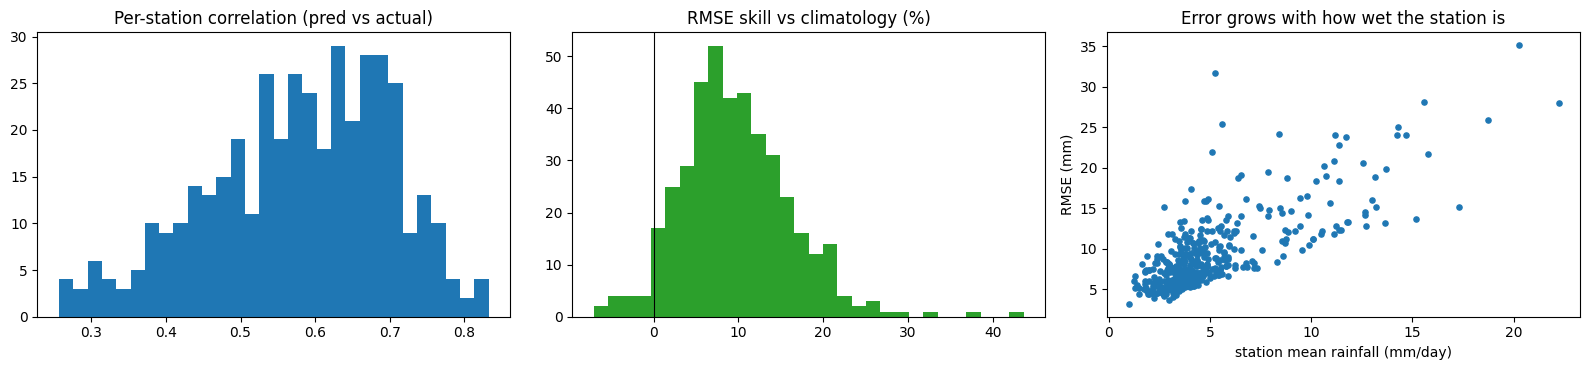

In [29]:
def station_stats(k, min_n=30):
    d = pd.DataFrame({"sid": R["station_id"].values, "a": y, "p": R[k].values})
    d["e"] = d["p"] - d["a"]; d["se"] = d["e"] ** 2; d["ae"] = d["e"].abs()
    g = d.groupby("sid")
    out = pd.DataFrame({"n": g.size(), "mean_actual": g["a"].mean(), "mean_pred": g["p"].mean(),
                        "RMSE": np.sqrt(g["se"].mean()), "MAE": g["ae"].mean(), "Bias": g["e"].mean()})
    out["corr"] = g.apply(lambda z: z["a"].corr(z["p"]))
    return out[out["n"] >= min_n].join(stations[["latitude", "longitude"]])

ST = {k: station_stats(k) for k in ["Climatology", "Persistence", BEST_NN]}
S  = ST[BEST_NN].copy()
S["skill_vs_clim"] = 100 * (1 - S["RMSE"] / ST["Climatology"]["RMSE"].reindex(S.index))
S["skill_vs_pers"] = 100 * (1 - S["RMSE"] / ST["Persistence"]["RMSE"].reindex(S.index))
S["name"] = S.index.str.split("|").str[0]
S.to_csv(os.path.join(ARTIFACT_DIR, "station_metrics_best_model.csv"))

print(f"{short(BEST_NN)}: {len(S)} stations with >= 30 test days")
print(f"  beats climatology (RMSE) at {100 * (S['skill_vs_clim'] > 0).mean():.0f}% of stations | beats persistence at {100 * (S['skill_vs_pers'] > 0).mean():.0f}% of stations")
print(f"  median per-station correlation {S['corr'].median():.2f} | median RMSE {S['RMSE'].median():.2f} mm | median |bias| {S['Bias'].abs().median():.2f} mm")
print("\n10 best stations by RMSE:");  display(S.sort_values("RMSE").head(10)[["name", "n", "mean_actual", "RMSE", "Bias", "corr", "skill_vs_clim"]].round(2))
print("10 worst stations by RMSE:"); display(S.sort_values("RMSE").tail(10)[["name", "n", "mean_actual", "RMSE", "Bias", "corr", "skill_vs_clim"]].round(2))

def smap(ax, v, ttl, cmap, sym=False):
    v = v.values.astype(float); lim = np.nanpercentile(np.abs(v), 98) if sym else None
    lo, hi = (-lim, lim) if sym else (np.nanpercentile(v, 2), np.nanpercentile(v, 98))
    sc = ax.scatter(S["longitude"], S["latitude"], c=v, s=34, cmap=cmap, vmin=lo, vmax=hi, edgecolor="k", lw=0.25)
    ax.set_title(ttl); ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_aspect("equal"); plt.colorbar(sc, ax=ax, fraction=0.04)
fig, axes = plt.subplots(1, 4, figsize=(24, 5.6))
smap(axes[0], S["mean_actual"], "Mean observed rainfall (mm/day)", "Blues")
smap(axes[1], S["RMSE"], f"RMSE (mm) - {short(BEST_NN)}", "magma_r")
smap(axes[2], S["Bias"], "Bias pred - actual (mm)", "RdBu_r", sym=True)
smap(axes[3], S["skill_vs_clim"], "RMSE skill vs climatology (%)\ngreen = model better", "RdYlGn", sym=True)
plt.tight_layout(); save_show("fig_station_maps")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].hist(S["corr"].dropna(), bins=30, color="tab:blue"); axes[0].set_title("Per-station correlation (pred vs actual)")
axes[1].hist(S["skill_vs_clim"].clip(-100, 100), bins=30, color="tab:green"); axes[1].axvline(0, color="k", lw=0.8); axes[1].set_title("RMSE skill vs climatology (%)")
axes[2].scatter(S["mean_actual"], S["RMSE"], s=14, c=S["elevation"] if "elevation" in S else "tab:blue"); axes[2].set_xlabel("station mean rainfall (mm/day)"); axes[2].set_ylabel("RMSE (mm)")
axes[2].set_title("Error grows with how wet the station is")
plt.tight_layout(); save_show("fig_station_distributions")

,metric,model,value,CI_low,CI_high,delta vs BiLSTM,delta CI_low,delta CI_high,P(better than ref)
0,RMSE,Climatology,11.588,10.730,12.413,1.067,0.861,1.273,0.000
1,RMSE,Persistence,12.871,11.960,13.784,2.349,1.917,2.796,0.000
2,RMSE,GBM (reference),11.032,10.198,11.862,0.511,0.371,0.642,0.000
3,RMSE,BiLSTM (cal),10.521,9.718,11.335,0.000,0.000,0.000,0.000
4,RMSE,BiLSTM-PINN (cal),10.491,9.687,11.303,-0.030,-0.089,0.027,0.840
5,RMSE,Transformer (cal),10.529,9.719,11.340,0.008,-0.070,0.095,0.433
6,MAE,Climatology,5.224,4.799,5.666,1.152,1.039,1.268,0.000
7,MAE,Persistence,4.759,4.299,5.280,0.687,0.580,0.801,0.000
8,MAE,GBM (reference),3.777,3.391,4.208,-0.295,-0.359,-0.232,1.000
9,MAE,BiLSTM (cal),4.072,3.678,4.510,0.000,0.000,0.000,0.000


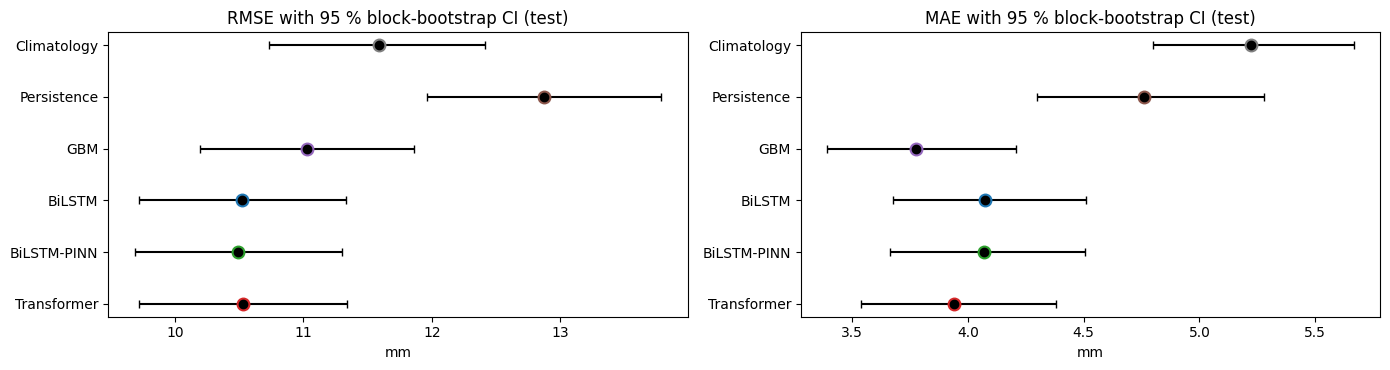

If the intervals of two models overlap heavily and the delta CI contains 0, their difference is within noise.


In [30]:
dkey = R["date"].dt.normalize().values
_, inv = np.unique(dkey, return_inverse=True); nd = inv.max() + 1
cnt_d = np.bincount(inv).astype(float)
SSE = np.stack([np.bincount(inv, weights=(R[k].values - y) ** 2) for k in ALL_MODELS], 1)          # (days, models)
SAE = np.stack([np.bincount(inv, weights=np.abs(R[k].values - y)) for k in ALL_MODELS], 1)
rng_bs = np.random.default_rng(0); B = 1000
idx = rng_bs.integers(0, nd, size=(B, nd))
den = cnt_d[idx].sum(1)[:, None]
BS = {"RMSE": np.sqrt(SSE[idx].sum(1) / den), "MAE": SAE[idx].sum(1) / den}
point = {"RMSE": np.sqrt(SSE.sum(0) / cnt_d.sum()), "MAE": SAE.sum(0) / cnt_d.sum()}
REFK = "BiLSTM (cal)" if "BiLSTM (cal)" in ALL_MODELS else NN_MODELS[0]; r_ = ALL_MODELS.index(REFK)

rows = []
for m in ["RMSE", "MAE"]:
    for jj, k in enumerate(ALL_MODELS):
        lo, hi = np.percentile(BS[m][:, jj], [2.5, 97.5]); d = BS[m][:, jj] - BS[m][:, r_]
        rows.append({"metric": m, "model": k, "value": point[m][jj], "CI_low": lo, "CI_high": hi,
                     f"delta vs {short(REFK)}": point[m][jj] - point[m][r_],
                     "delta CI_low": np.percentile(d, 2.5), "delta CI_high": np.percentile(d, 97.5), "P(better than ref)": float((d < 0).mean())})
CI = pd.DataFrame(rows); CI.to_csv(os.path.join(ARTIFACT_DIR, "bootstrap_ci.csv"), index=False)
display(CI.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, m in zip(axes, ["RMSE", "MAE"]):
    d = CI[CI["metric"] == m].reset_index(drop=True)
    ax.errorbar(d["value"], range(len(d)), xerr=[d["value"] - d["CI_low"], d["CI_high"] - d["value"]], fmt="o", color="k", capsize=3)
    for i, k in enumerate(d["model"]): ax.plot(d["value"][i], i, "o", color=MCOL[k], ms=9)
    ax.set_yticks(range(len(d))); ax.set_yticklabels([short(k) for k in d["model"]]); ax.invert_yaxis()
    ax.set_title(f"{m} with 95 % block-bootstrap CI (test)"); ax.set_xlabel("mm")
plt.tight_layout(); save_show("fig_bootstrap_ci")
print("If the intervals of two models overlap heavily and the delta CI contains 0, their difference is within noise.")

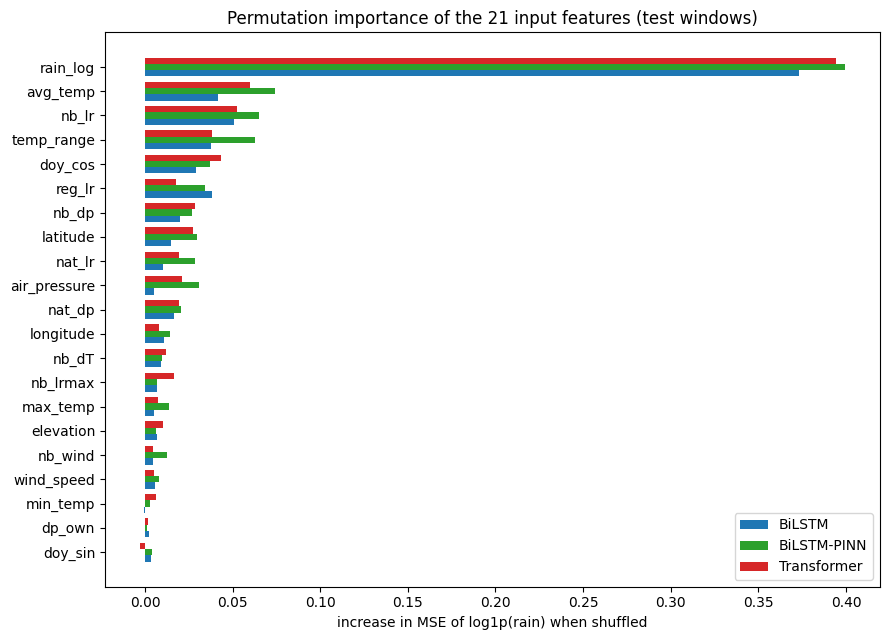

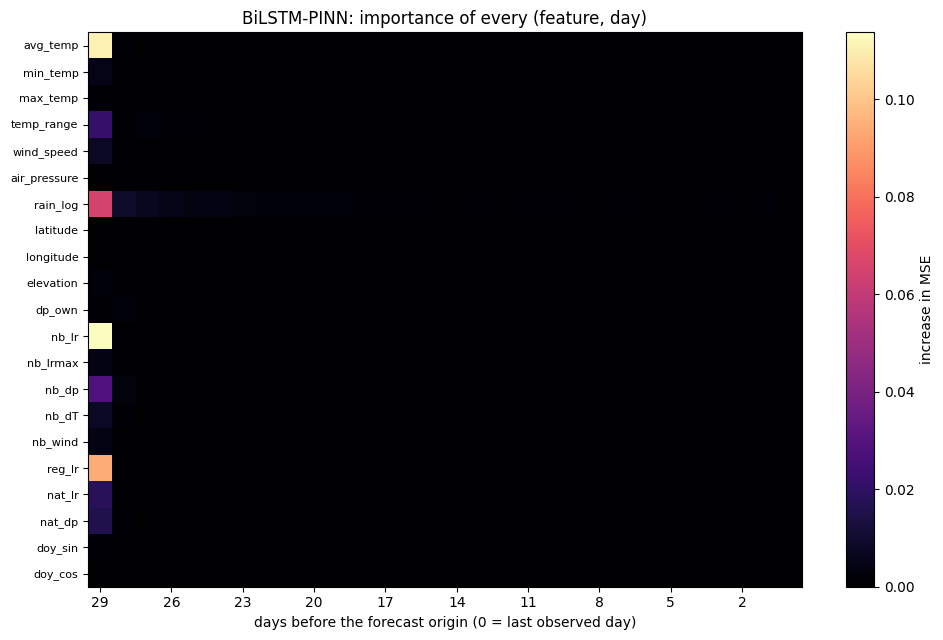

In [31]:
IMP_N = 12000
_rng  = np.random.default_rng(SEED)
_sel  = np.sort(_rng.choice(tgt_idx["test"], size=min(IMP_N, len(tgt_idx["test"])), replace=False))
_t    = torch.as_tensor(_sel, dtype=torch.long, device=device)
_offs = torch.arange(-SEQ_LEN + 1, 1, dtype=torch.long, device=device)
Xw    = X_t[(_t - HORIZON)[:, None] + _offs[None, :]]                    # (N, SEQ_LEN, N_FEAT) test windows
yt    = Y_t[_t]
_g    = torch.Generator(device="cpu"); _g.manual_seed(SEED)
perm  = torch.randperm(len(_t), generator=_g).to(device)
Xperm = Xw[perm]                                                         # the same windows in shuffled order

@torch.no_grad()
def mse_log(model, Xin, yy):
    model.eval(); outs = []
    for s in range(0, len(Xin), 4096):
        o = model(Xin[s:s + 4096]).float(); outs.append(o[:, 0] if o.ndim == 2 else o)
    return float(((torch.cat(outs) - yy) ** 2).mean())

def feature_importance(model):
    base = mse_log(model, Xw, yt); out = {}
    for fi, fn in enumerate(FEATURES):
        Xp = Xw.clone(); Xp[:, :, fi] = Xperm[:, :, fi]                  # shuffle one feature over the whole window
        out[fn] = mse_log(model, Xp, yt) - base
    return base, pd.Series(out)

IMP, BASE = {}, {}
for k in NN_MODELS: BASE[k], IMP[k] = feature_importance(NN_OBJ[k])
IMP_DF = pd.DataFrame(IMP); IMP_DF.columns = [short(c) for c in IMP_DF.columns]
IMP_DF.to_csv(os.path.join(ARTIFACT_DIR, "permutation_importance.csv"))
order = IMP_DF.mean(axis=1).sort_values().index
fig, ax = plt.subplots(figsize=(9, 6.5)); yy = np.arange(len(order)); hh = 0.26
for i, k in enumerate(NN_MODELS): ax.barh(yy + (i - 1) * hh, IMP_DF.loc[order, short(k)], hh, color=MCOL[k], label=short(k))
ax.set_yticks(yy); ax.set_yticklabels(order); ax.set_xlabel("increase in MSE of log1p(rain) when shuffled"); ax.set_title("Permutation importance of the 21 input features (test windows)")
ax.legend(); plt.tight_layout(); save_show("fig_permutation_importance")

# ---- feature x lag grid for the best network (also drawn in 3-D in section 9.10) ----
Xw_s, Xp_s, yt_s = Xw[:6000], Xperm[:6000], yt[:6000]
_mdl = NN_OBJ[BEST_NN]; _base = mse_log(_mdl, Xw_s, yt_s)
IMP_GRID = np.zeros((SEQ_LEN, N_FEAT))                                   # [position in window (0 = oldest day), feature]
for l in range(SEQ_LEN):
    for fi in range(N_FEAT):
        Xp = Xw_s.clone(); Xp[:, l, fi] = Xp_s[:, l, fi]
        IMP_GRID[l, fi] = mse_log(_mdl, Xp, yt_s) - _base
fig, ax = plt.subplots(figsize=(10, 6.5))
im = ax.imshow(np.clip(IMP_GRID, 0, None).T[:, ::-1], aspect="auto", cmap="magma")
ax.set_yticks(range(N_FEAT)); ax.set_yticklabels(FEATURES, fontsize=8)
ax.set_xticks(range(0, SEQ_LEN, 3)); ax.set_xticklabels([str(d) for d in range(SEQ_LEN - 1, -1, -1)][::3]); ax.set_xlabel("days before the forecast origin (0 = last observed day)")
ax.set_title(f"{short(BEST_NN)}: importance of every (feature, day)"); plt.colorbar(im, label="increase in MSE"); plt.tight_layout(); save_show("fig_importance_feature_lag")

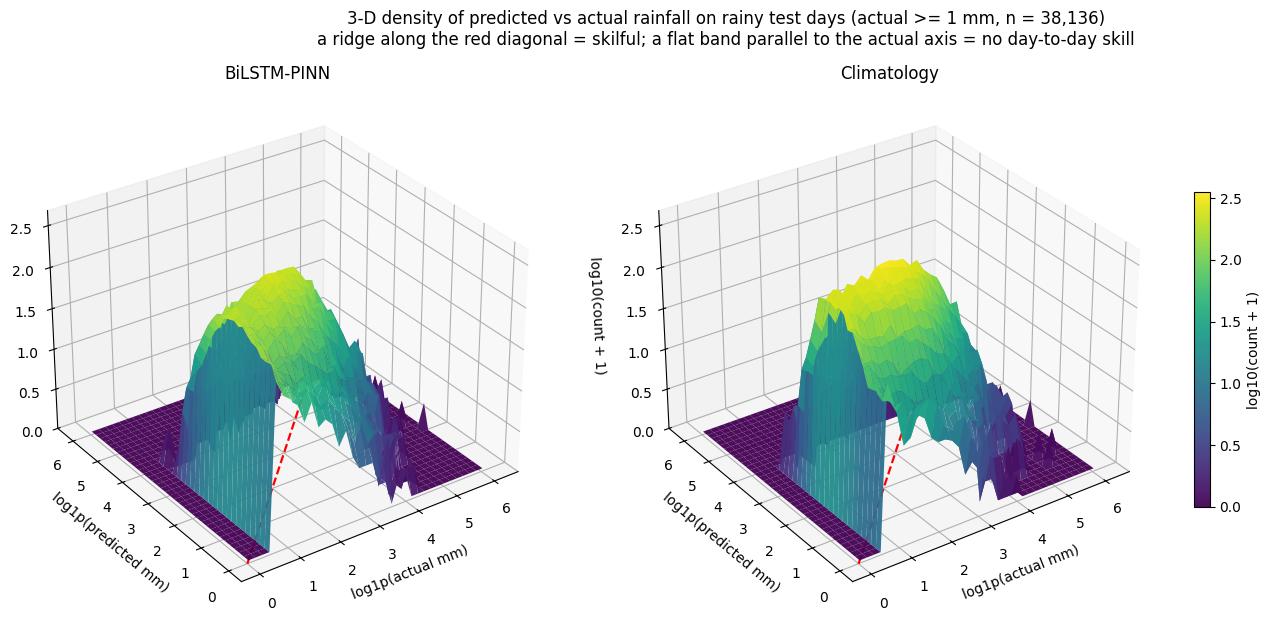

In [32]:
# ---- 3-D (a): density surface of actual vs predicted rainfall for RAINY days (ridge on the diagonal = good model) ----
wet = y >= RAIN_DAY_MM                                   # dry days (~half of all days) would form one giant spike and hide everything else
def density_grid(name, nb=36):
    la, lp = np.log1p(y[wet]), np.log1p(R[name].values[wet]); mx = float(np.log1p(y.max()))
    H2, xe, ye = np.histogram2d(la, lp, bins=nb, range=[[0, mx], [0, mx]])
    xc, yc = (xe[:-1] + xe[1:]) / 2, (ye[:-1] + ye[1:]) / 2
    Xg, Yg = np.meshgrid(xc, yc, indexing="ij")
    return (Xg, Yg, np.log10(H2 + 1)), mx
shown = [BEST_NN, "Climatology"]
grids = {nm: density_grid(nm) for nm in shown}; zmax = max(g[0][2].max() for g in grids.values())
fig = plt.figure(figsize=(17, 7))
for i, nm in enumerate(shown):
    (Xg, Yg, Zg), mx = grids[nm]; ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    sf = ax.plot_surface(Xg, Yg, Zg, cmap="viridis", vmin=0, vmax=zmax, linewidth=0, antialiased=True, alpha=0.95)
    ax.plot([0, mx], [0, mx], [0, 0], "r--", lw=1.6); ax.set_zlim(0, zmax * 1.05)
    ax.set_xlabel("log1p(actual mm)"); ax.set_ylabel("log1p(predicted mm)"); ax.set_zlabel("log10(count + 1)", labelpad=8)
    ax.set_title(short(nm)); ax.view_init(elev=30, azim=-125)
fig.subplots_adjust(left=0.07, right=0.9, wspace=0.12, top=0.86)
fig.colorbar(sf, ax=fig.axes, shrink=0.6, pad=0.03, label="log10(count + 1)")
fig.suptitle(f"3-D density of predicted vs actual rainfall on rainy test days (actual >= {RAIN_DAY_MM:g} mm, n = {int(wet.sum()):,})\n"
             "a ridge along the red diagonal = skilful; a flat band parallel to the actual axis = no day-to-day skill", y=0.97)
save_show("fig3d_density_surface")

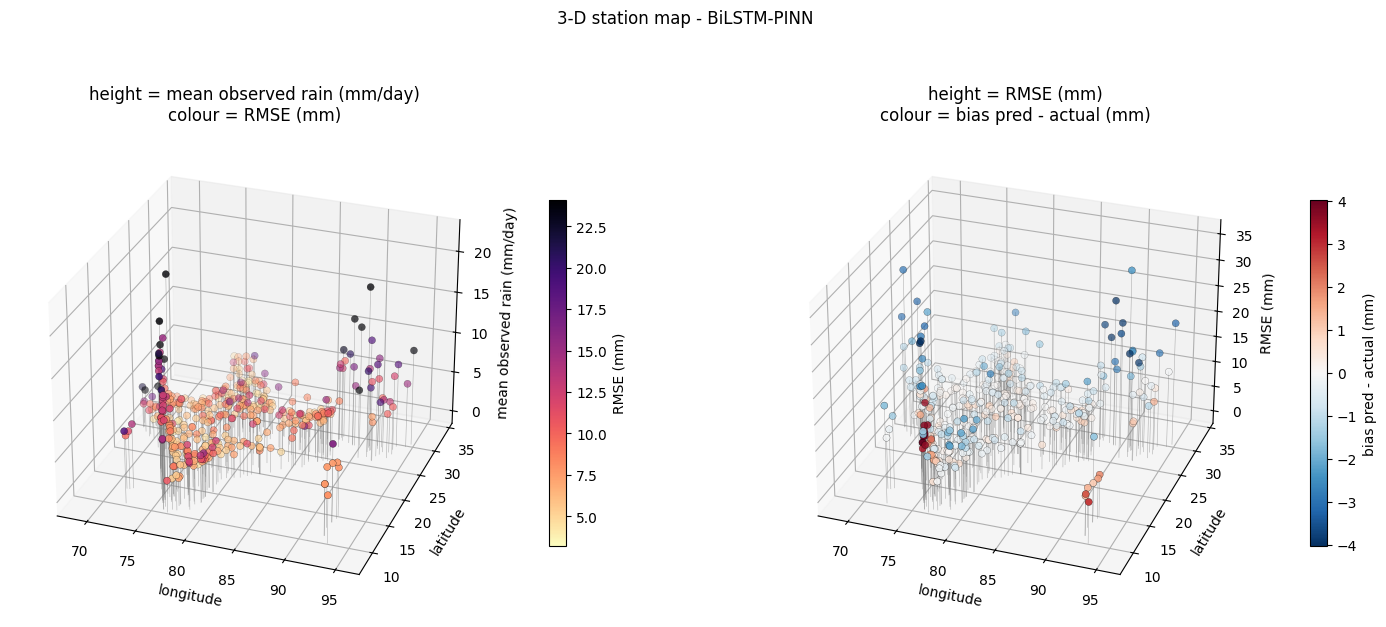

In [33]:
# ---- 3-D (b): station map - x = longitude, y = latitude, z = error / rainfall, colour = bias ----
fig = plt.figure(figsize=(18, 7.5))
for i, (zcol, ccol, cmap, zl, cl, sym) in enumerate([("mean_actual", "RMSE", "magma_r", "mean observed rain (mm/day)", "RMSE (mm)", False),
                                                      ("RMSE", "Bias", "RdBu_r", "RMSE (mm)", "bias pred - actual (mm)", True)]):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    c = S[ccol].values; lim = np.nanpercentile(np.abs(c), 98)
    for lo_, la_, z_ in zip(S["longitude"], S["latitude"], S[zcol]): ax.plot([lo_, lo_], [la_, la_], [0, z_], color="gray", lw=0.4, alpha=0.6)
    sc = ax.scatter(S["longitude"], S["latitude"], S[zcol], c=c, cmap=cmap, s=26, vmin=-lim if sym else None, vmax=lim if sym else np.nanpercentile(c, 98), depthshade=True, edgecolor="k", lw=0.2)
    ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_zlabel(zl); ax.view_init(elev=28, azim=-70)
    fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.08, label=cl); ax.set_title(f"height = {zl}\ncolour = {cl}")
fig.suptitle(f"3-D station map - {short(BEST_NN)}", y=0.98); save_show("fig3d_station_map")

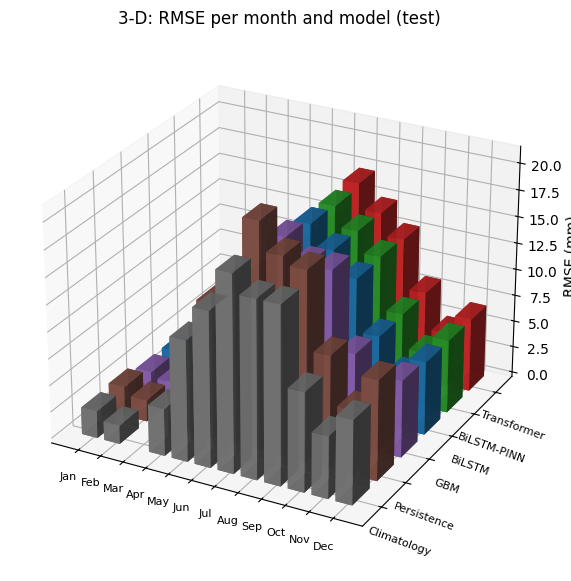

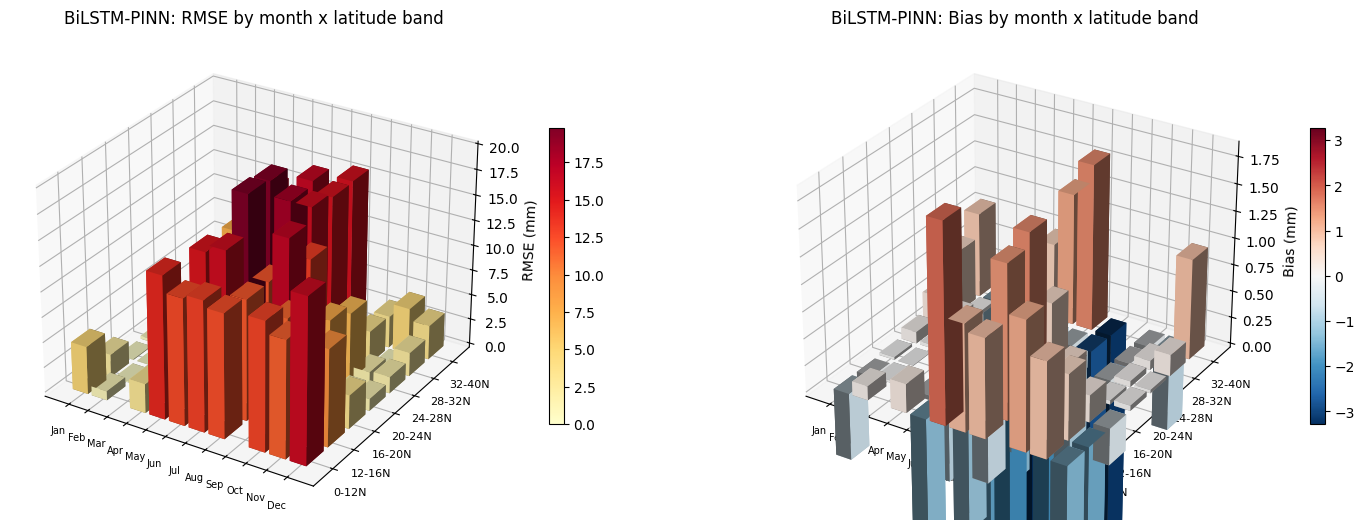

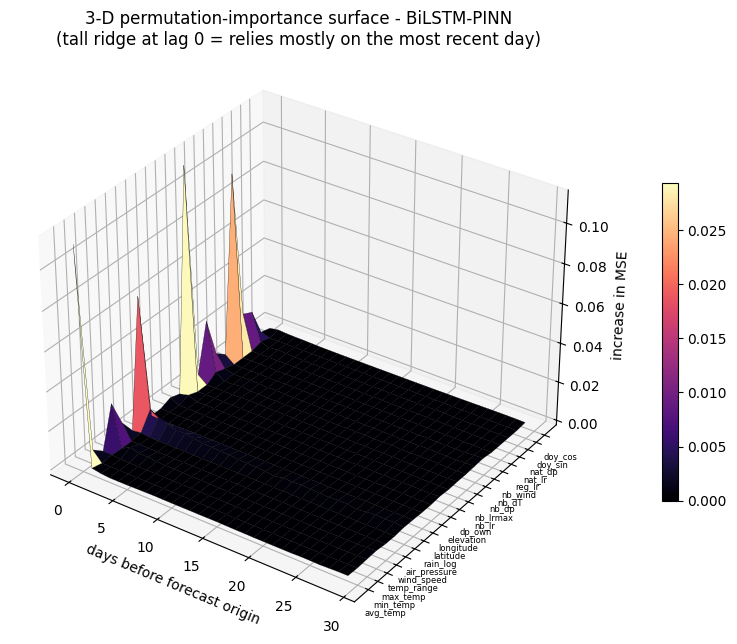

In [34]:
# ---- 3-D (c): month x model bars of RMSE ----
mods = ALL_MODELS
fig = plt.figure(figsize=(14, 7)); ax = fig.add_subplot(111, projection="3d")
for jj, k in enumerate(mods):
    z = rmse_m[k].values; valid = ~np.isnan(z); n_ = int(valid.sum())
    ax.bar3d(months[valid] - 0.35, np.full(n_, jj) - 0.35, np.zeros(n_), 0.7, 0.7, z[valid], color=MCOL[k], alpha=0.88, shade=True)
ax.set_xticks(months); ax.set_xticklabels(MN, fontsize=8)
ax.set_yticks(range(len(mods))); ax.set_yticklabels([short(k) for k in mods], fontsize=8, rotation=-20)
ax.set_zlabel("RMSE (mm)"); ax.set_title("3-D: RMSE per month and model (test)"); ax.view_init(elev=26, azim=-62)
save_show("fig3d_month_model_rmse")

# ---- 3-D (d): latitude band x month bars for the best network (RMSE and bias) ----
LAT_EDGES = np.array([0, 12, 16, 20, 24, 28, 32, 40]); BAND_LAB = [f"{a}-{b}N" for a, b in zip(LAT_EDGES[:-1], LAT_EDGES[1:])]
band = np.digitize(R["lat"].values, LAT_EDGES) - 1
Z = {"RMSE": np.full((12, len(BAND_LAB)), np.nan), "Bias": np.full((12, len(BAND_LAB)), np.nan)}
for mth in months:
    for b in range(len(BAND_LAB)):
        msk = (R["month"].values == mth) & (band == b)
        if msk.sum() >= 100:
            e = R[BEST_NN].values[msk] - y[msk]; Z["RMSE"][mth - 1, b] = np.sqrt(np.mean(e ** 2)); Z["Bias"][mth - 1, b] = e.mean()
fig = plt.figure(figsize=(18, 7))
for i, (nm, cmap, sym) in enumerate([("RMSE", "YlOrRd", False), ("Bias", "RdBu_r", True)]):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d"); Mx = Z[nm]; valid = ~np.isnan(Mx); mi, bi = np.where(valid); v = Mx[valid]
    norm = plt.Normalize(-np.abs(v).max() if sym else 0, np.abs(v).max() if sym else v.max())
    ax.bar3d(mi + 1 - 0.4, bi - 0.4, np.zeros(len(v)), 0.8, 0.8, v, color=plt.get_cmap(cmap)(norm(v)), shade=True)
    ax.set_xticks(months); ax.set_xticklabels(MN, fontsize=7); ax.set_yticks(range(len(BAND_LAB))); ax.set_yticklabels(BAND_LAB, fontsize=8)
    ax.set_zlabel(f"{nm} (mm)"); ax.set_title(f"{short(BEST_NN)}: {nm} by month x latitude band"); ax.view_init(elev=28, azim=-58)
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.55, pad=0.08)
save_show("fig3d_lat_month")

# ---- 3-D (e): feature x lag importance surface (from 9.9) ----
Gs = np.clip(IMP_GRID, 0, None); lag_days = np.arange(SEQ_LEN - 1, -1, -1)
Xg, Yg = np.meshgrid(lag_days, np.arange(N_FEAT), indexing="ij")
fig = plt.figure(figsize=(12, 7.5)); ax = fig.add_subplot(111, projection="3d")
sf = ax.plot_surface(Xg, Yg, Gs, cmap="magma", linewidth=0.2, edgecolor="k", antialiased=True)
ax.set_xlabel("days before forecast origin"); ax.set_yticks(range(N_FEAT)); ax.set_yticklabels(FEATURES, fontsize=6); ax.set_zlabel("increase in MSE")
ax.set_title(f"3-D permutation-importance surface - {short(BEST_NN)}\n(tall ridge at lag 0 = relies mostly on the most recent day)"); ax.view_init(elev=32, azim=-55)
fig.colorbar(sf, shrink=0.55, pad=0.08); save_show("fig3d_importance_surface")

In [35]:
# ---- interactive, rotatable 3-D station map (plotly; skipped silently if plotly is not installed) ----
try:
    import plotly.express as px
    P = S.reset_index(drop=True).assign(size=S["mean_actual"].values + 0.5)
    fig = px.scatter_3d(P, x="longitude", y="latitude", z="RMSE", color="Bias", size="size", hover_name="name",
                        hover_data={"mean_actual": ":.2f", "corr": ":.2f", "skill_vs_clim": ":.1f", "size": False},
                        color_continuous_scale="RdBu_r", color_continuous_midpoint=0, title=f"Station RMSE (height) and bias (colour) - {short(BEST_NN)}")
    fig.update_layout(height=650, margin=dict(l=0, r=0, t=50, b=0)); fig.write_html(os.path.join(ARTIFACT_DIR, "station_map_3d.html")); fig.show()
except ImportError:
    print("plotly not installed - run `pip install plotly` to get the interactive 3-D map (the static versions above are unaffected).")

In [36]:
with open(os.path.join(ARTIFACT_DIR, "preprocessing.pkl"), "wb") as f:
    pickle.dump(dict(scaler=scaler, FEATURES=FEATURES, CONT_COLS=CONT_COLS, SEQ_LEN=SEQ_LEN, HORIZON=HORIZON,
                     BILSTM_CFG=BILSTM_CFG, TRF_CFG=TRF_CFG, train_cut=train_cut, val_cut=val_cut,
                     AUX_COLS=AUX_COLS, DT_MAX=DT_MAX, DP_MAX=DP_MAX), f)
print("Saved:", sorted(os.listdir(ARTIFACT_DIR)))

def forecast_rainfall(model, recent_raw, network_raw, scale=1.0):
    """recent_raw : raw rows for ONE station: >= SEQ_LEN consecutive days, no missing values, ending on the forecast origin.
       network_raw: raw rows of the WHOLE station network for the same days PLUS the day before the first one
                    (needed for neighbour / regional features; NaN allowed).
       scale      : optional mm-calibration factor (e.g. CAL['BiLSTM']).
       Returns (forecast_date, rainfall_mm)."""
    rr = recent_raw.copy()
    rr["date_of_record"] = pd.to_datetime(rr["date_of_record"])
    rr["station_id"] = make_station_id(rr)
    assert rr["station_id"].nunique() == 1, "pass exactly one station"
    rr = rr.sort_values("date_of_record").tail(SEQ_LEN).reset_index(drop=True)
    assert len(rr) == SEQ_LEN and (rr["date_of_record"].iloc[-1] - rr["date_of_record"].iloc[0]).days == SEQ_LEN - 1, \
        f"need {SEQ_LEN} consecutive daily rows"
    assert rr[NEEDED].notna().all().all() and (rr["max_temp"] <= 50).all(), "the window must not contain missing/invalid values"
    net = network_raw.copy()
    net["date_of_record"] = pd.to_datetime(net["date_of_record"]); net["station_id"] = make_station_id(net)
    reg = regional_features(net)
    rr = rr.drop(columns=[c for c in REG_COLS if c in rr.columns]).merge(reg[["date_of_record", "station_id"] + REG_COLS],
                                                                          on=["date_of_record", "station_id"], how="left")
    rr[REG_COLS] = rr[REG_COLS].fillna(REG_FILL)
    f = make_features(rr)
    f[CONT_COLS] = scaler.transform(f[CONT_COLS])
    x = f[FEATURES].values.astype("float32")
    model.eval()
    with torch.no_grad():
        o = model(torch.from_numpy(x[None]).to(device)).flatten()
        p = o[0].item()                      # rain is output 0 for every model (BiLSTM-PINN also returns 5 weather-state values)
    return rr["date_of_record"].iloc[-1] + pd.Timedelta(days=HORIZON), float(max(np.expm1(p), 0.0)) * scale

# ---- demo + consistency check: re-forecast the LAST test window from raw rows ----
row = tgt_idx["test"][-1]
window = daily.iloc[row - H - SEQ_LEN + 1: row - H + 1]
net_rows = raw[(raw["date_of_record"] >= window["date_of_record"].iloc[0] - pd.Timedelta(days=1)) &
               (raw["date_of_record"] <= window["date_of_record"].iloc[-1])]
fdate, p_lstm = forecast_rainfall(bilstm, window, net_rows)
_,     p_pinn = forecast_rainfall(bilstm_pinn, window, net_rows)
_,     p_trf  = forecast_rainfall(transformer, window, net_rows)
print(f"Station: {sid[row].split('|')[0]} | forecast for {fdate.date()}   (uncalibrated; multiply by CAL[model] for the mm-calibrated value)")
print(f"  BiLSTM      : {p_lstm:6.2f} mm   (batch pipeline gave {predictions['BiLSTM']['test'][-1]:6.2f})")
print(f"  BiLSTM-PINN : {p_pinn:6.2f} mm   (batch pipeline gave {predictions['BiLSTM-PINN']['test'][-1]:6.2f})")
print(f"  Transformer : {p_trf:6.2f} mm   (batch pipeline gave {predictions['Transformer']['test'][-1]:6.2f})")
print(f"  Actual      : {rain_mm[row]:6.2f} mm")


Saved: ['BiLSTM_PINN_best.pt', 'BiLSTM_PINN_history.csv', 'BiLSTM_best.pt', 'BiLSTM_history.csv', 'Transformer_best.pt', 'Transformer_history.csv', 'bootstrap_ci.csv', 'error_by_intensity.csv', 'event_scores.csv', 'fig3d_density_surface.png', 'fig3d_importance_surface.png', 'fig3d_lat_month.png', 'fig3d_month_model_rmse.png', 'fig3d_station_map.png', 'fig_bootstrap_ci.png', 'fig_calibration_residuals.png', 'fig_classification.png', 'fig_error_by_intensity.png', 'fig_event_detection.png', 'fig_importance_feature_lag.png', 'fig_metric_bars.png', 'fig_monthly.png', 'fig_permutation_importance.png', 'fig_station_distributions.png', 'fig_station_maps.png', 'permutation_importance.csv', 'preprocessing.pkl', 'results.csv', 'station_map_3d.html', 'station_metrics_best_model.csv', 'test_predictions.csv']
Station: Yercaud | forecast for 2025-02-10   (uncalibrated; multiply by CAL[model] for the mm-calibrated value)
  BiLSTM      :   0.05 mm   (batch pipeline gave   0.05)
  BiLSTM-PINN :   0.01 m